# Суздаль: исследование на BlocksNet

Ноутбук читает локальный PBF-файл Geofabrik, режет территорию на кварталы, строит пешеходный граф и считает показатели BlocksNet. Территория — **Суздаль** (OSM relation `1390203`, площадь около 15 км²). Граф — пешеходный, скорость 5 км/ч. Из сервисов рассматриваются только школы, как в `examples/pipeline.ipynb`.

Порядок работы:

1. Граница города.
2. Кварталы и землепользование.
3. Здания и население.
4. **STOP**: проверяем число кварталов и решаем, считать ли матрицу по всем кварталам или только по населённым.
5. Школы.
6. Пешеходный граф.
7. Матрица доступности.
8. Школьная обеспеченность.
9. Плотность и морфотипы.
10. Area accessibility.
11. Итоговые файлы и проверки.

**Важно:** население, площадь застройки и вместимость школ — оценки на основе OSM и коэффициентов BlocksNet, а не официальная статистика. Первый запуск скачивает PBF-файл Geofabrik (~841 МБ) и может занять несколько минут; повторные запуски читают его с диска.

Все результаты сохраняются в `examples/data/suzdal/`.

## 1. Параметры и папки

In [8]:
from pathlib import Path
import hashlib
import json
import os
import pickle
import tempfile
import time
import warnings
from datetime import datetime, timezone
from importlib.metadata import version

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
from shapely.geometry import box

import iduedu as ie
from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes
from blocksnet.analysis.network import area_accessibility
from blocksnet.analysis.provision import competitive_provision
from blocksnet.blocks.aggregation import aggregate_objects
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.blocks.cutting import cut_urban_blocks, preprocess_urban_objects
from blocksnet.config import service_types_config
from blocksnet.enums import LandUse
from blocksnet.preprocessing.imputing import impute_buildings, impute_services
from blocksnet.relations import calculate_accessibility_matrix

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (10, 10)

BOUNDARY_QUERY = "Суздаль, Владимирская область, Россия"
OSM_RELATION_ID = 1390203
DISTRICT_NAME = "Суздаль"
WALK_SPEED_KMH = 5.0
LIVING_DEMAND = 30
MAX_BLOCKS_WARN = 3000
FORCE_RELOAD = False
FORCE_GRAPH_RELOAD = False


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    return start


def now_utc() -> str:
    return datetime.now(timezone.utc).isoformat()


def safe_float(value):
    try:
        result = float(value)
    except (TypeError, ValueError):
        return None
    return result if np.isfinite(result) else None


def write_geojson(gdf: gpd.GeoDataFrame, path: Path) -> None:
    out = gdf.copy()
    for column in out.columns:
        if column == "geometry":
            continue
        if out[column].dtype == object:
            out[column] = out[column].apply(
                lambda value: value.value
                if hasattr(value, "value") and not isinstance(value, str)
                else value
            )
            if out[column].apply(lambda value: isinstance(value, (list, dict, tuple, set))).any():
                out[column] = out[column].astype(str)
    if out.crs is None:
        out = out.set_crs(4326)
    if len(out) > 0:
        out.to_crs(4326).to_file(path, driver="GeoJSON")


def package_version(name: str):
    try:
        return version(name)
    except Exception:
        return None


PROJECT_ROOT = find_project_root(Path.cwd())
BASE_DIR = PROJECT_ROOT / "examples" / "data" / "suzdal"
PBF_URL = "https://download.geofabrik.de/russia/central-fed-district-latest.osm.pbf"
PBF_PATH = BASE_DIR / "central-fed-district-latest.osm.pbf"
PYROSM_TMP_DIR = BASE_DIR / "tmp"
RAW_DIR = BASE_DIR / "raw"
CACHE_DIR = BASE_DIR / "cache"
OUT_DIR = BASE_DIR / "results"
for folder in (RAW_DIR, CACHE_DIR, OUT_DIR, PYROSM_TMP_DIR):
    folder.mkdir(parents=True, exist_ok=True)
tempfile.tempdir = str(PYROSM_TMP_DIR)
os.environ["TMPDIR"] = str(PYROSM_TMP_DIR)
os.environ["TEMP"] = str(PYROSM_TMP_DIR)
os.environ["TMP"] = str(PYROSM_TMP_DIR)

ox.settings.use_cache = True
ox.settings.cache_folder = str(CACHE_DIR / "osmnx")
ox.settings.requests_timeout = 300

print(f"Проект: {PROJECT_ROOT}")
print(f"Территория: {DISTRICT_NAME}")
print(f"OSM relation: {OSM_RELATION_ID}")
print(f"Пешеходная скорость: {WALK_SPEED_KMH} км/ч")
print(f"PBF: {PBF_PATH}")
print(f"Временная папка Pyrosm: {PYROSM_TMP_DIR}")
print(f"Папка результатов: {OUT_DIR}")


Проект: d:\Учеба\ai-course\python-package-boilerplate
Территория: Суздаль
OSM relation: 1390203
Пешеходная скорость: 5.0 км/ч
PBF: d:\Учеба\ai-course\python-package-boilerplate\examples\data\suzdal\central-fed-district-latest.osm.pbf
Временная папка Pyrosm: d:\Учеба\ai-course\python-package-boilerplate\examples\data\suzdal\tmp
Папка результатов: d:\Учеба\ai-course\python-package-boilerplate\examples\data\suzdal\results


## 2. Граница города

Читаю границу из кэша
Площадь города: 15.0 км²
Границы: [40.4190217 56.399337  40.4769505 56.4554768]


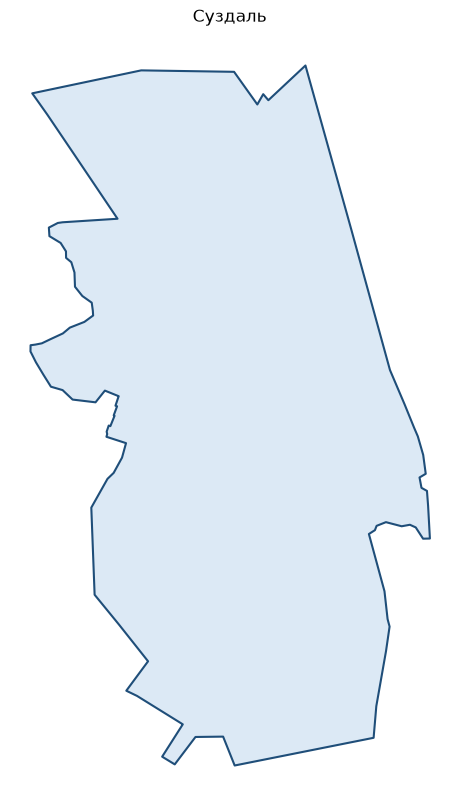

In [9]:
boundary_path = RAW_DIR / "boundary.geojson"

if boundary_path.exists() and not FORCE_RELOAD:
    print("Читаю границу из кэша")
    boundaries = gpd.read_file(boundary_path)
else:
    print("Запрашиваю границу в Nominatim")
    boundaries = ox.geocode_to_gdf(BOUNDARY_QUERY, which_result=1)
    if len(boundaries) != 1:
        boundaries = ox.geocode_to_gdf(f"R{OSM_RELATION_ID}", byid=True)
    if len(boundaries) != 1:
        raise ValueError("Не удалось однозначно определить границу города")
    osm_type = str(boundaries.iloc[0].get("osm_type", ""))
    osm_id = int(boundaries.iloc[0].get("osm_id", -1))
    if osm_type != "relation" or osm_id != OSM_RELATION_ID:
        boundaries = ox.geocode_to_gdf(f"R{OSM_RELATION_ID}", byid=True)
    write_geojson(boundaries, boundary_path)

boundaries = boundaries[["geometry"]].copy()
boundaries = boundaries[
    boundaries.geometry.notna() & ~boundaries.geometry.is_empty
].reset_index(drop=True)
if len(boundaries) != 1:
    raise ValueError("Граница должна состоять из одного объекта")

boundary_4326 = boundaries.to_crs(4326)
boundary_union_4326 = boundary_4326.union_all()
boundary_projected = boundary_4326.to_crs(boundary_4326.estimate_utm_crs())
boundary_area_km2 = float(boundary_projected.area.sum() / 1e6)

if not 10 <= boundary_area_km2 <= 25:
    print("ВНИМАНИЕ: площадь отличается от ожидаемых ~15 км²")

print(f"Площадь города: {boundary_area_km2:.1f} км²")
print(f"Границы: {boundary_4326.total_bounds}")

boundary_4326.plot(facecolor="#dce9f5", edgecolor="#1f4e79", linewidth=1.5)
plt.title("Суздаль")
plt.axis("off")
plt.show()


## 3. Кварталы и землепользование

Кварталы режутся по дорогам, воде и железным дорогам, затем им назначается `land_use`. Карта ниже показывает геометрию кварталов, а карта после назначения — категории землепользования.


Данные OSM читаются локально из PBF-файла Geofabrik (`central-fed-district-latest.osm.pbf`) через `pyrosm`; Overpass не используется. Файл скачивается один раз (~841 МБ) в `examples/data/suzdal/` и затем читается с диска. Для Суздаля из PBF выбирается только bounding box города.

In [10]:
from pyrosm import OSM
import requests

roads_tags = {
    "highway": [
        "construction",
        "crossing",
        "living_street",
        "motorway",
        "motorway_link",
        "motorway_junction",
        "pedestrian",
        "primary",
        "primary_link",
        "raceway",
        "residential",
        "road",
        "secondary",
        "secondary_link",
        "service",
        "services",
        "tertiary",
        "tertiary_link",
        "track",
        "trunk",
        "trunk_link",
        "turning_circle",
        "turning_loop",
        "unclassified",
    ],
}
water_filter = {
    "natural": ["water", "bay"],
    "waterway": ["river", "canal", "ditch"],
    "landuse": ["basin", "reservoir"],
    "water": ["lake", "reservoir", "pond", "canal", "river", "basin"],
}

if not PBF_PATH.exists() or PBF_PATH.stat().st_size == 0 or FORCE_RELOAD:
    part_path = PBF_PATH.with_suffix(PBF_PATH.suffix + ".part")
    existing = part_path.stat().st_size if part_path.exists() else 0
    headers = {"Range": f"bytes={existing}-"} if existing else {}
    print(f"Скачивание Geofabrik PBF: {PBF_URL}")
    with requests.get(
        PBF_URL,
        headers=headers,
        stream=True,
        timeout=(30, 300),
    ) as response:
        if response.status_code == 416:
            part_path.replace(PBF_PATH)
        else:
            response.raise_for_status()
            append = existing > 0 and response.status_code == 206
            if not append:
                existing = 0
            total = existing + int(response.headers.get("Content-Length", 0))
            last_mark = 0
            with open(part_path, "ab" if append else "wb") as file:
                done = existing
                for chunk in response.iter_content(1024 * 1024):
                    if not chunk:
                        continue
                    file.write(chunk)
                    done += len(chunk)
                    mark = done // (100 * 1024 * 1024)
                    if mark > last_mark:
                        last_mark = mark
                        print(
                            f"  {done / 1024**2:.0f} МБ"
                            + (f" / {total / 1024**2:.0f} МБ" if total else "")
                        )
            part_path.replace(PBF_PATH)
else:
    print(f"PBF из кэша: {PBF_PATH.name}")

if not PBF_PATH.exists() or PBF_PATH.stat().st_size == 0:
    raise FileNotFoundError(f"Не удалось скачать PBF: {PBF_PATH}")

print(f"PBF: {PBF_PATH} ({PBF_PATH.stat().st_size / 1024**2:.0f} МБ)")
pbf_osm = OSM(
    str(PBF_PATH),
    bounding_box=list(boundary_4326.total_bounds),
    engine="out_of_core",
)


def _empty_gdf():
    return gpd.GeoDataFrame(geometry=[], crs=4326)


def _as_gdf(value):
    if value is None:
        return _empty_gdf()
    if value.crs is None:
        value = value.set_crs(4326)
    return value


def load_osm_features(name: str, tags=None) -> gpd.GeoDataFrame:
    path = RAW_DIR / f"{name}.geojson"
    if path.exists() and not FORCE_RELOAD:
        print(f"Кэш: {path.name}")
        return gpd.read_file(path)
    print(f"Чтение OSM из PBF: {name}")
    if name == "roads":
        features = pbf_osm.get_data_by_custom_criteria(
            custom_filter={"highway": roads_tags["highway"]},
            keep_other_tags=False,
        )
    elif name == "railways":
        features = pbf_osm.get_data_by_custom_criteria(
            custom_filter={"railway": ["rail"]},
            keep_other_tags=False,
        )
    elif name == "water":
        features = pbf_osm.get_data_by_custom_criteria(
            custom_filter=water_filter,
            keep_other_tags=False,
        )
    elif name == "functional_zones":
        features = pbf_osm.get_landuse()
    elif name == "buildings":
        features = pbf_osm.get_buildings(
            extra_attributes=["building:levels"],
        )
    elif name == "schools":
        features = pbf_osm.get_data_by_custom_criteria(
            custom_filter={"amenity": ["school"]},
            extra_attributes=["capacity"],
            keep_other_tags=False,
        )
    else:
        raise ValueError(f"Неизвестный слой OSM: {name}")
    features = _as_gdf(features).reset_index(drop=True)
    if features.empty:
        print(f"OSM не вернул объекты: {name}")
        return features
    write_geojson(features, path)
    return features


roads = load_osm_features("roads", roads_tags)
railways = load_osm_features("railways", {"railway": "rail"})
water = load_osm_features("water", water_filter)
functional_zones = load_osm_features("functional_zones", {"landuse": True})
buildings = load_osm_features("buildings", {"building": True})
schools = load_osm_features("schools", {"amenity": "school"})

print(f"Дороги: {len(roads)}")
print(f"Железные дороги: {len(railways)}")
print(f"Водные объекты: {len(water)}")
print(f"Зоны landuse: {len(functional_zones)}")
print(f"Здания: {len(buildings)}")
print(f"Школы: {len(schools)}")


PBF из кэша: central-fed-district-latest.osm.pbf
PBF: d:\Учеба\ai-course\python-package-boilerplate\examples\data\suzdal\central-fed-district-latest.osm.pbf (841 МБ)
Кэш: roads.geojson
Чтение OSM из PBF: railways
OSM не вернул объекты: railways
Кэш: water.geojson
Кэш: functional_zones.geojson


d:\Учеба\ai-course\python-package-boilerplate\.venv\Lib\site-packages\pyrosm\_log.py:149: UserWarning: Could not find any OSM data for given area.
  return func(*args, **kwargs)


Кэш: buildings.geojson
Кэш: schools.geojson
Дороги: 1064
Железные дороги: 0
Водные объекты: 43
Зоны landuse: 285
Здания: 4135
Школы: 4


In [11]:
roads = roads[
    roads.geom_type.isin(["LineString", "MultiLineString"])
].copy()
railways = railways[
    railways.geom_type.isin(["LineString", "MultiLineString"])
].copy()
water = water[
    water.geom_type.isin(
        ["Polygon", "MultiPolygon", "LineString", "MultiLineString"]
    )
].copy()
functional_zones = functional_zones[
    functional_zones.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

for name, gdf in [
    ("roads", roads),
    ("railways", railways),
    ("water", water),
    ("functional_zones", functional_zones),
]:
    if not gdf.empty:
        gdf = gdf[gdf.geometry.is_valid & ~gdf.geometry.is_empty].copy()
    if name == "roads":
        roads = gdf
    elif name == "railways":
        railways = gdf
    elif name == "water":
        water = gdf
    else:
        functional_zones = gdf

local_crs = boundary_4326.estimate_utm_crs()
boundaries_projected = boundary_4326.to_crs(local_crs)

if not roads.empty:
    roads = roads.to_crs(local_crs)
if not railways.empty:
    railways = railways.to_crs(local_crs)
if not water.empty:
    water = water.to_crs(local_crs)
if not functional_zones.empty:
    functional_zones = functional_zones.to_crs(local_crs)

lines, polygons = preprocess_urban_objects(
    roads if not roads.empty else None,
    railways if not railways.empty else None,
    water if not water.empty else None,
)
blocks = cut_urban_blocks(
    boundaries_projected,
    lines,
    polygons,
).reset_index(drop=True)
blocks["site_area"] = blocks.area

write_geojson(blocks, OUT_DIR / "blocks_raw.geojson")

print(f"Кварталов: {len(blocks)}")
print(f"Площадь кварталов: {blocks.area.sum() / 1e6:.1f} км²")
print(f"CRS: {blocks.crs}")


2026-10-23 00:15:23.325 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema
2026-10-23 00:15:23.345 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema
2026-10-23 00:15:23.347 | WARNING  | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:53 - Creating empty railways
2026-10-23 00:15:23.353 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema
2026-10-23 00:15:23.380 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:51 - Checking boundaries schema
2026-10-23 00:15:23.394 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:55 - Checking line objects schema
2026-10-23 00:15:23.418 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:62 - Checking polygon objects schema
2026-10-23 00:15:23.439 | INFO

Кварталов: 299
Площадь кварталов: 14.9 км²
CRS: EPSG:32637


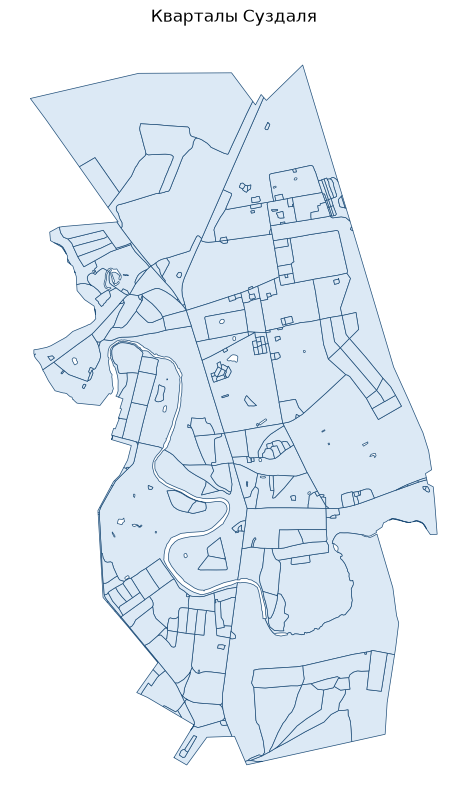

In [12]:
fig, ax = plt.subplots(figsize=(10, 10))
blocks.plot(
    ax=ax,
    facecolor="#dce9f5",
    edgecolor="#1f4e79",
    linewidth=0.5,
)
ax.set_title("Кварталы Суздаля")
ax.set_axis_off()
plt.show()


land_use
LandUse.RESIDENTIAL    138
None                   103
LandUse.INDUSTRIAL      32
LandUse.RECREATION      11
LandUse.AGRICULTURE      8
LandUse.SPECIAL          7
Name: count, dtype: int64


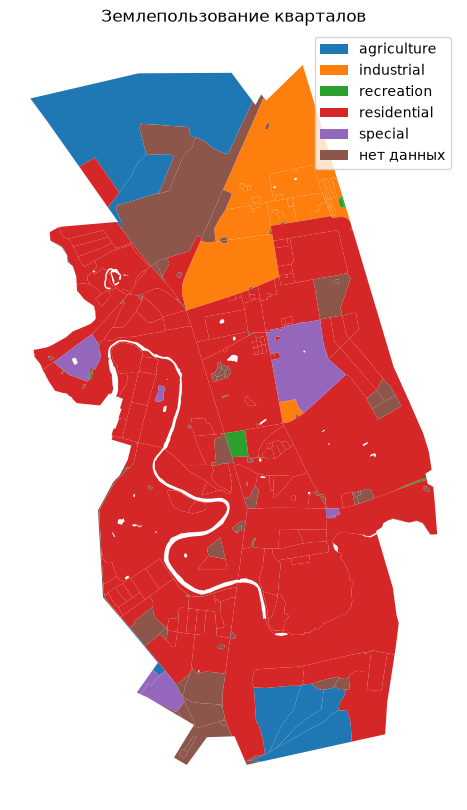

In [13]:
land_use_rules = {
    "commercial": LandUse.BUSINESS,
    "industrial": LandUse.INDUSTRIAL,
    "cemetery": LandUse.SPECIAL,
    "garages": LandUse.INDUSTRIAL,
    "residential": LandUse.RESIDENTIAL,
    "retail": LandUse.BUSINESS,
    "grass": LandUse.RECREATION,
    "farmland": LandUse.AGRICULTURE,
    "construction": LandUse.SPECIAL,
    "brownfield": LandUse.INDUSTRIAL,
    "forest": LandUse.RECREATION,
    "recreation_ground": LandUse.RECREATION,
    "religious": LandUse.SPECIAL,
    "flowerbed": LandUse.RECREATION,
    "military": LandUse.SPECIAL,
    "landfill": LandUse.TRANSPORT,
    "meadow": LandUse.AGRICULTURE,
    "orchard": LandUse.AGRICULTURE,
    "allotments": LandUse.AGRICULTURE,
    "farmyard": LandUse.AGRICULTURE,
    "quarry": LandUse.INDUSTRIAL,
}

if functional_zones.empty:
    blocks["land_use"] = np.nan
else:
    zones = (
        functional_zones.reset_index(drop=True)[["geometry", "landuse"]]
        .rename(columns={"landuse": "functional_zone"})
    )
    zones["functional_zone"] = zones["functional_zone"].astype(str)
    blocks = assign_land_use(blocks, zones, land_use_rules)

blocks["site_area"] = blocks.area
write_geojson(blocks, OUT_DIR / "blocks_land_use.geojson")

print(blocks["land_use"].value_counts(dropna=False))
land_use_plot = blocks.copy()
land_use_plot["land_use"] = land_use_plot["land_use"].apply(
    lambda value: value.value if hasattr(value, "value") else "нет данных"
)
land_use_plot.plot(column="land_use", legend=True, figsize=(10, 10))
plt.title("Землепользование кварталов")
plt.axis("off")
plt.show()


## 4. Здания и население

Здания агрегируются по кварталам; `population` — расчётная оценка BlocksNet по жилой площади. Карта ниже показывает, где сосредоточено население: это не перепись, а модельная оценка.


In [14]:
buildings = load_osm_features("buildings", {"building": True})
buildings = buildings[
    buildings.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()
buildings = buildings[
    buildings.geometry.is_valid & ~buildings.geometry.is_empty
].copy()
if buildings.empty:
    raise ValueError("В OSM не найдено зданий на территории города")

buildings = buildings.to_crs(local_crs)
is_living_tags = [
    "residential",
    "house",
    "apartments",
    "detached",
    "terrace",
    "dormitory",
]
buildings["is_living"] = buildings["building"].isin(is_living_tags)

if "building:levels" in buildings.columns:
    buildings["number_of_floors"] = pd.to_numeric(
        buildings["building:levels"], errors="coerce"
    )
else:
    buildings["number_of_floors"] = np.nan

buildings = impute_buildings(
    buildings,
    default_living_demand=LIVING_DEMAND,
)
buildings_blocks, excess_buildings = aggregate_objects(blocks, buildings)
buildings_blocks["site_area"] = buildings_blocks.area

write_geojson(buildings_blocks, OUT_DIR / "buildings_blocks.geojson")
if len(excess_buildings) > 0:
    write_geojson(excess_buildings, OUT_DIR / "excess_buildings.geojson")

population_total = float(buildings_blocks["population"].sum())
blocks_with_buildings = int((buildings_blocks["build_floor_area"] > 0).sum())
blocks_with_population = int((buildings_blocks["population"] > 0).sum())

print(f"Зданий: {len(buildings)}")
print(f"Население: {population_total:,.0f}".replace(",", " "))
print(f"Кварталов с застройкой: {blocks_with_buildings}")
print(f"Кварталов с населением: {blocks_with_population}")


Кэш: buildings.geojson


2026-10-23 00:15:43.605 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column footprint_area not found and will be initialized as None
2026-10-23 00:15:43.606 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column build_floor_area not found and will be initialized as None
2026-10-23 00:15:43.607 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column living_area not found and will be initialized as None
2026-10-23 00:15:43.608 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column non_living_area not found and will be initialized as None
2026-10-23 00:15:43.609 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column population not found and will be initialized as None
2026-10-23 00:15:43.719 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-23 00:15:43.

Зданий: 4135
Население: 9 497
Кварталов с застройкой: 186
Кварталов с населением: 89


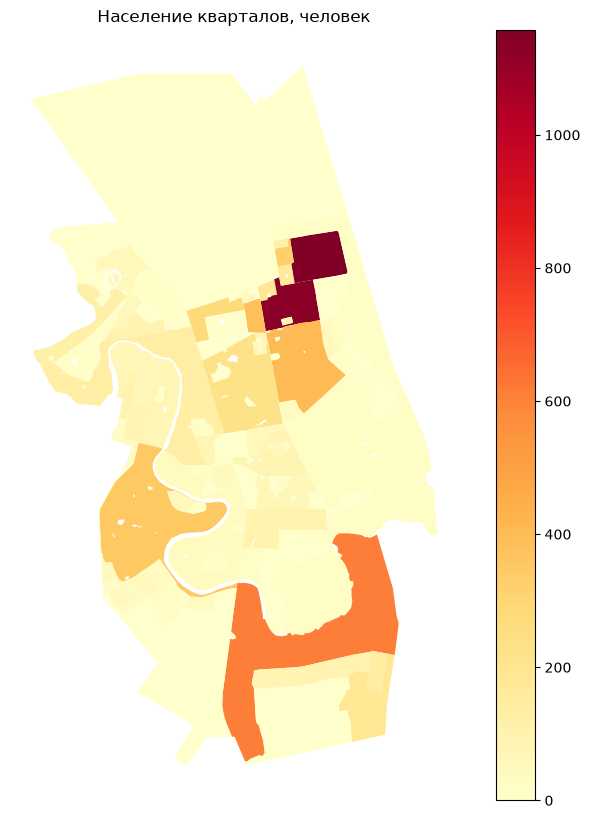

In [15]:
fig, ax = plt.subplots(figsize=(10, 10))
population_map = blocks.join(buildings_blocks[["population"]])
population_map.plot(
    column="population",
    cmap="YlOrRd",
    legend=True,
    ax=ax,
    missing_kwds={"color": "#f2f2f2"},
)
ax.set_title("Население кварталов, человек")
ax.set_axis_off()
plt.show()


In [16]:
block_area_km2 = float(blocks.area.sum() / 1e6)
land_use_nan_share = float(blocks["land_use"].isna().mean())
land_use_counts = {
    str(key.value if hasattr(key, "value") else key): int(value)
    for key, value in blocks["land_use"].value_counts(dropna=False).items()
}
MATRIX_SCOPE = "all"

checkpoint = {
    "created_at": now_utc(),
    "territory": DISTRICT_NAME,
    "boundary_area_km2": boundary_area_km2,
    "block_area_km2": block_area_km2,
    "block_count": int(len(blocks)),
    "blocks_with_buildings": blocks_with_buildings,
    "blocks_with_population": blocks_with_population,
    "population_total": population_total,
    "land_use_nan_share": land_use_nan_share,
    "land_use_counts": land_use_counts,
    "matrix_scope": MATRIX_SCOPE,
}
with open(
    OUT_DIR / "blocks_checkpoint.json", "w", encoding="utf-8"
) as file:
    json.dump(checkpoint, file, ensure_ascii=False, indent=2)

print(f"Кварталов: {len(blocks)}")
print(f"Площадь кварталов: {block_area_km2:.1f} км²")
print(f"Население: {population_total:,.0f}".replace(",", " "))
print(f"Кварталов с застройкой: {blocks_with_buildings}")
print(f"Кварталов с населением: {blocks_with_population}")
print(f"Доля кварталов без land use: {land_use_nan_share:.1%}")
print("Распределение land use:")
print(blocks["land_use"].value_counts(dropna=False))

if len(blocks) > MAX_BLOCKS_WARN:
    print(
        "ВНИМАНИЕ: кварталов много. Для матрицы можно установить "
        "MATRIX_SCOPE = 'populated' в этой ячейке и выполнить её снова."
    )

print("STOP: не запускайте следующие ячейки, пока не согласуем метрики.")


Кварталов: 299
Площадь кварталов: 14.9 км²
Население: 9 497
Кварталов с застройкой: 186
Кварталов с населением: 89
Доля кварталов без land use: 34.4%
Распределение land use:
land_use
LandUse.RESIDENTIAL    138
None                   103
LandUse.INDUSTRIAL      32
LandUse.RECREATION      11
LandUse.AGRICULTURE      8
LandUse.SPECIAL          7
Name: count, dtype: int64
STOP: не запускайте следующие ячейки, пока не согласуем метрики.


## STOP

Проверьте вывод выше и файл `blocks_checkpoint.json`.

Если кварталов слишком много, измените в ячейке выше:

```python
MATRIX_SCOPE = "populated"
```

и выполните эту ячейку снова. Тогда матрица доступности и школьная обеспеченность будут считаться только для кварталов, где есть население или вместимость школ. Карты и итоговый GeoJSON по-прежнему будут содержать все кварталы.

После проверки запускайте следующие ячейки.


## 5. Школы

Школы агрегируются по кварталам, а вместимость при отсутствии в OSM восстанавливается через `impute_services`. Карта ниже показывает вместимость по кварталам; пустой квартал означает отсутствие школьной вместимости именно в нём, а не в городе.


In [17]:
schools = load_osm_features("schools", {"amenity": "school"})
schools = schools[
    schools.geom_type.isin(
        ["Polygon", "MultiPolygon", "Point", "MultiPoint"]
    )
].copy()
schools = schools[
    schools.geometry.is_valid & ~schools.geometry.is_empty
].copy()
if schools.empty:
    raise ValueError("В OSM не найдено школ на территории города")

schools = schools.to_crs(local_crs)
if "capacity" in schools.columns:
    schools["capacity"] = pd.to_numeric(
        schools["capacity"], errors="coerce"
    )
schools = impute_services(schools, "school")
schools_blocks, excess_schools = aggregate_objects(blocks, schools)

write_geojson(schools_blocks, OUT_DIR / "schools_blocks.geojson")
if len(excess_schools) > 0:
    write_geojson(excess_schools, OUT_DIR / "excess_schools.geojson")

school_capacity_total = float(schools_blocks["capacity"].sum())
blocks_with_school_capacity = int(
    (schools_blocks["capacity"] > 0).sum()
)

print(f"Школ: {len(schools)}")
print(f"Суммарная вместимость: {school_capacity_total:,.0f}".replace(",", " "))
print(f"Кварталов со школами: {blocks_with_school_capacity}")


2026-10-23 00:16:01.449 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-23 00:16:01.451 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


Кэш: schools.geojson
Школ: 4
Суммарная вместимость: 1 000
Кварталов со школами: 4


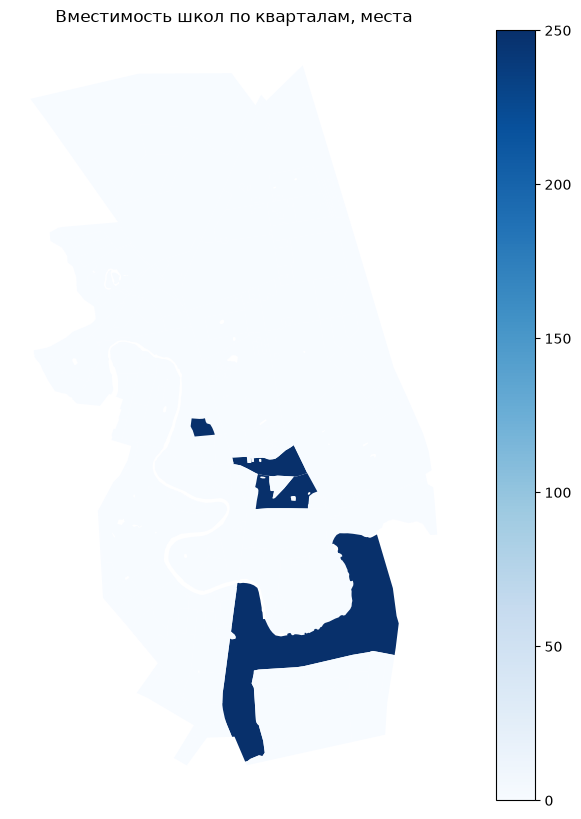

In [18]:
fig, ax = plt.subplots(figsize=(10, 10))
capacity_map = blocks.join(schools_blocks[["capacity"]])
capacity_map.plot(
    column="capacity",
    cmap="Blues",
    legend=True,
    ax=ax,
    missing_kwds={"color": "#f2f2f2"},
)
ax.set_title("Вместимость школ по кварталам, места")
ax.set_axis_off()
plt.show()


## 6. Пешеходный граф

Строю пешеходный граф из локального PBF.


Reading central-fed-district-latest.osm.pbf:  21%|##1       | 186M/882M [00:02<00:08, 84.4MB/s]

2026-10-23 00:16:42.876 | WARNING  | iduedu.utils.utils:remove_weakly_connected_nodes:27 - Found 2 disconnected subgraphs in the network. These are isolated groups of nodes with no connections between them. Size of components: [2211, 3]
2026-10-23 00:16:42.891 | WARNING  | iduedu.utils.utils:remove_weakly_connected_nodes:37 - Removing 3 nodes that form 1 trap components. These are groups where you can enter but can't exit (or vice versa). Keeping the largest strongly connected component (2211 nodes).


Узлов: 2 211
Рёбер: 5 832
Компонент связности: 1
Медиана time_min: 0.43 мин


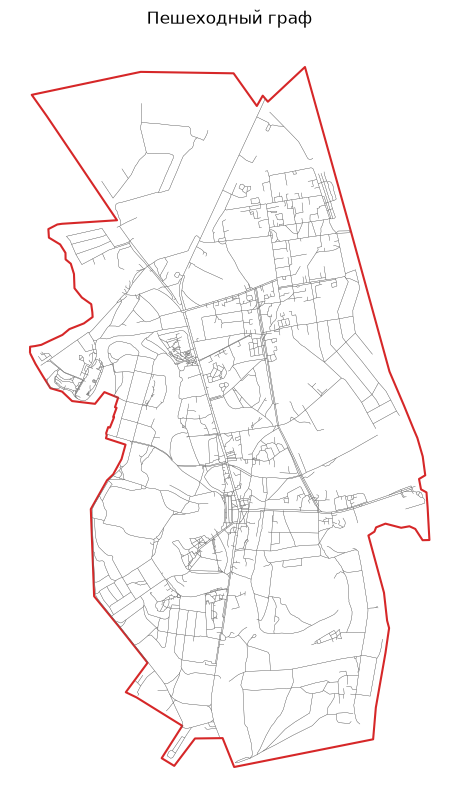

In [19]:
from pyrosm import OSM
from iduedu.utils.utils import remove_weakly_connected_nodes

graph_path = CACHE_DIR / "walk_graph.pkl"
graph_meta_path = CACHE_DIR / "walk_graph_meta.json"
boundary_hash = hashlib.sha256(
    boundary_4326.geometry.to_wkb().iloc[0]
).hexdigest()
pbf_mtime_ns = PBF_PATH.stat().st_mtime_ns

old_meta = {}
if graph_meta_path.exists():
    with open(graph_meta_path, "r", encoding="utf-8") as file:
        old_meta = json.load(file)

rebuild_graph = (
    FORCE_GRAPH_RELOAD
    or not graph_path.exists()
    or not graph_meta_path.exists()
    or old_meta.get("boundary_hash") != boundary_hash
    or old_meta.get("pbf_mtime_ns") != pbf_mtime_ns
    or float(old_meta.get("walk_speed_kmh", -1)) != WALK_SPEED_KMH
)

if rebuild_graph:
    print("Строю пешеходный граф из локального PBF.")
    graph_osm = OSM(
        str(PBF_PATH),
        bounding_box=list(boundary_4326.total_bounds),
        engine="out_of_core",
    )
    graph = graph_osm.get_graph(
        network_type="walking",
        graph_type="networkx",
        osmnx_compatible=True,
    )
    if graph is None or graph.number_of_nodes() == 0:
        raise ValueError("В PBF не найден пешеходный граф")
    graph = ox.truncate.truncate_graph_polygon(
        graph,
        boundary_union_4326,
        truncate_by_edge=False,
    )
    local_crs = boundary_4326.estimate_utm_crs()
    walk_speed = WALK_SPEED_KMH * 1000 / 60
    nodes, edges = ox.graph_to_gdfs(graph)
    nodes = nodes.to_crs(local_crs)
    nodes["x"] = nodes.geometry.x
    nodes["y"] = nodes.geometry.y
    nodes = nodes[["x", "y", "geometry"]]
    edges = edges.reset_index().to_crs(local_crs)
    edges["length_meter"] = edges.geometry.length.round(3)
    edges["time_min"] = (edges.geometry.length / walk_speed).round(3)
    edges["type"] = "walk"
    edges = edges[
        ["u", "v", "key", "length_meter", "time_min", "type", "geometry"]
    ].set_index(["u", "v", "key"])
    graph = ox.graph_from_gdfs(nodes, edges)
    graph = remove_weakly_connected_nodes(graph)
    graph = nx.relabel_nodes(
        graph,
        {old_label: new_label for new_label, old_label in enumerate(graph.nodes())},
    )
    graph.graph["crs"] = local_crs.to_epsg()
    graph.graph["walk_speed"] = walk_speed
    graph.graph["type"] = "walk"
    with open(graph_path, "wb") as file:
        pickle.dump(graph, file)
else:
    print("Читаю пешеходный граф из кэша")
    with open(graph_path, "rb") as file:
        graph = pickle.load(file)

edge_times = np.array(
    [data["time_min"] for *_, data in graph.edges(data=True)],
    dtype=float,
)
if len(edge_times) == 0:
    raise ValueError("В графе нет рёбер с time_min")

if graph.is_directed():
    graph_components = nx.number_weakly_connected_components(graph)
else:
    graph_components = nx.number_connected_components(graph)

graph_meta = {
    "created_at": old_meta.get("created_at", now_utc())
    if not rebuild_graph
    else now_utc(),
    "source": "OpenStreetMap via Geofabrik PBF + Pyrosm",
    "pbf_file": PBF_PATH.name,
    "pbf_mtime_ns": pbf_mtime_ns,
    "boundary_hash": boundary_hash,
    "walk_speed_kmh": WALK_SPEED_KMH,
    "crs": str(graph.graph.get("crs")),
    "nodes": int(graph.number_of_nodes()),
    "edges": int(graph.number_of_edges()),
    "components": int(graph_components),
    "time_min_median": float(np.median(edge_times)),
    "time_min_p95": float(np.percentile(edge_times, 95)),
}
with open(graph_meta_path, "w", encoding="utf-8") as file:
    json.dump(graph_meta, file, ensure_ascii=False, indent=2)

nodes_gdf, edges_gdf = ox.graph_to_gdfs(graph)
write_geojson(
    nodes_gdf.reset_index(drop=True),
    CACHE_DIR / "walk_graph_nodes.geojson",
)
write_geojson(
    edges_gdf.reset_index(drop=True),
    CACHE_DIR / "walk_graph_edges.geojson",
)

print(f"Узлов: {graph.number_of_nodes():,}".replace(",", " "))
print(f"Рёбер: {graph.number_of_edges():,}".replace(",", " "))
print(f"Компонент связности: {graph_components}")
print(f"Медиана time_min: {graph_meta['time_min_median']:.2f} мин")

plot_edges = edges_gdf.to_crs(4326)
if len(plot_edges) > 20000:
    plot_edges = plot_edges.sample(20000, random_state=42)

fig, ax = plt.subplots(figsize=(10, 10))
boundary_4326.boundary.plot(
    ax=ax, color="#d62728", linewidth=1.5
)
plot_edges.plot(ax=ax, color="#666666", linewidth=0.2)
ax.set_title("Пешеходный граф")
ax.set_axis_off()
plt.show()


## 7. Матрица доступности

`acc_mx[i, j]` — время пешего пути от квартала `i` до квартала `j` в минутах. Гистограмма показывает распределение времён, таблица ниже — первые строки и столбцы; полная матрица сохраняется в `accessibility_matrix.csv`.


Кварталов в матрице: 299
Считаю матрицу доступности. Это может занять несколько минут.
Размер матрицы: (299, 299)
Доля конечных значений: 100.0%
Медиана: 30.686424255371094 мин
95-й перцентиль: 61.17153549194336 мин
Файл: d:\Учеба\ai-course\python-package-boilerplate\examples\data\suzdal\results\accessibility_matrix.csv


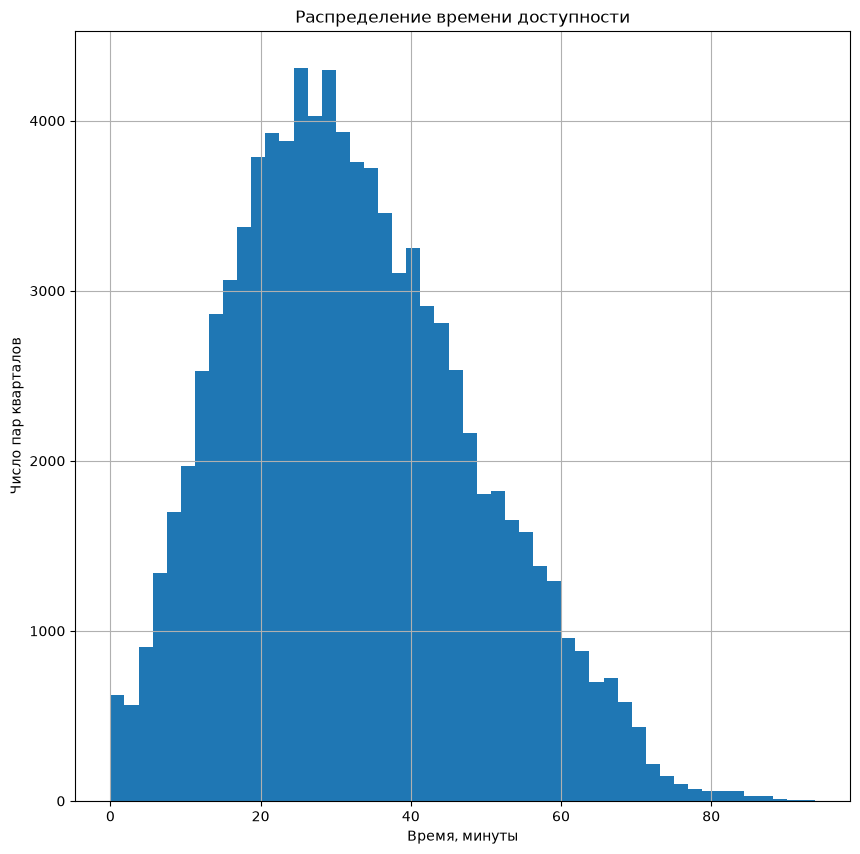

In [20]:
eligible_mask = (
    buildings_blocks["population"].reindex(blocks.index, fill_value=0)
    > 0
) | (
    schools_blocks["capacity"].reindex(blocks.index, fill_value=0) > 0
)

if MATRIX_SCOPE == "all":
    blocks_for_matrix = blocks.copy()
elif MATRIX_SCOPE == "populated":
    blocks_for_matrix = blocks.loc[eligible_mask].copy()
else:
    raise ValueError("MATRIX_SCOPE должен быть 'all' или 'populated'")

if blocks_for_matrix.empty:
    raise ValueError("Нет кварталов для матрицы доступности")

print(f"Кварталов в матрице: {len(blocks_for_matrix)}")
print("Считаю матрицу доступности. Это может занять несколько минут.")

acc_mx = calculate_accessibility_matrix(
    blocks_for_matrix,
    graph,
    weight_key="time_min",
    dtype=np.float32,
)
matrix_values = acc_mx.to_numpy()
finite_values = matrix_values[np.isfinite(matrix_values)]
matrix_finite_share = float(np.isfinite(matrix_values).mean())
matrix_stats = {
    "rows": int(acc_mx.shape[0]),
    "columns": int(acc_mx.shape[1]),
    "finite_share": matrix_finite_share,
    "median_min": safe_float(np.median(finite_values))
    if len(finite_values)
    else None,
    "p95_min": safe_float(np.percentile(finite_values, 95))
    if len(finite_values)
    else None,
    "max_min": safe_float(np.max(finite_values))
    if len(finite_values)
    else None,
}

if len(acc_mx) <= MAX_BLOCKS_WARN:
    matrix_path = OUT_DIR / "accessibility_matrix.csv"
    acc_mx.to_csv(matrix_path, float_format="%.3f")
else:
    matrix_path = OUT_DIR / "accessibility_matrix.csv.gz"
    acc_mx.to_csv(
        matrix_path,
        float_format="%.3f",
        compression="gzip",
    )

print(f"Размер матрицы: {acc_mx.shape}")
print(f"Доля конечных значений: {matrix_finite_share:.1%}")
print(f"Медиана: {matrix_stats['median_min']} мин")
print(f"95-й перцентиль: {matrix_stats['p95_min']} мин")
print(f"Файл: {matrix_path}")

if len(finite_values):
    pd.Series(finite_values).hist(bins=50)
    plt.xlabel("Время, минуты")
    plt.ylabel("Число пар кварталов")
    plt.title("Распределение времени доступности")
    plt.show()


In [21]:
from IPython.display import display

display(acc_mx.iloc[:5, :5])
print(f"Показаны первые 5×5 значений из матрицы {acc_mx.shape}.")


,0,1,2,3,4
0,0.000000,10.853638,5.246195,3.957719,34.562202
1,10.853638,0.000000,7.664402,7.355926,33.320408
2,5.246195,7.664402,0.000000,3.308483,31.532967
3,3.957719,7.355926,3.308483,0.000000,33.024490
4,34.562202,34.080410,31.532967,33.024490,0.000000


Показаны первые 5×5 значений из матрицы (299, 299).


## 8. Школьная обеспеченность

`competitive_provision` распределяет спрос на школы по доступной вместимости. Карта `provision_strong` показывает долю спроса в пределах 15 минут; ниже — все поля `prov_df`, связи `links_df`, а также `provision_weak`, разрыв `weak − strong` и остатки спроса и вместимости.


2026-10-23 00:17:58.896 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-10-23 00:17:58.898 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter
2026-10-23 00:17:58.924 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities
2026-10-23 00:17:58.929 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached


Тип сервиса: школа
Норматив: 120 мест на 1000 жителей
Порог доступности: 15 минут


2026-10-23 00:17:59.779 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


Спрос на школы: 1 183
Покрыто в пределах порога: 398
Обеспеченность: 33.6%


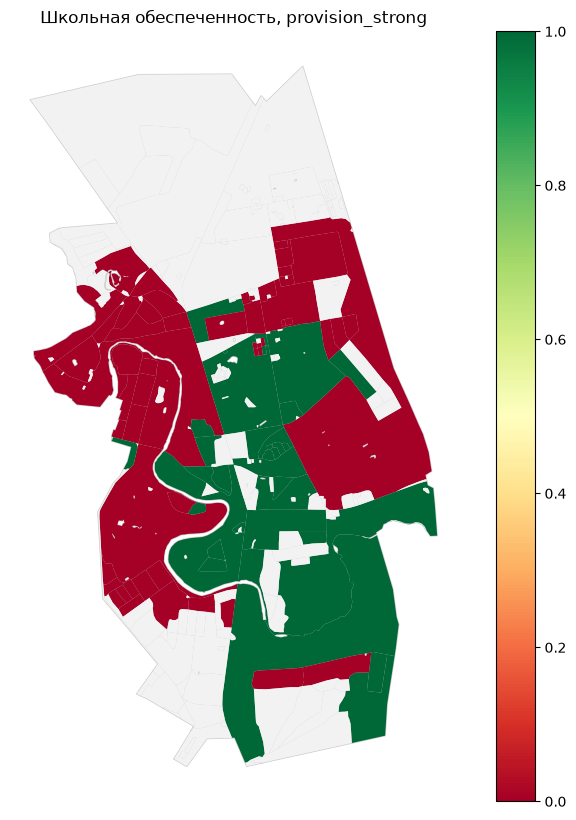

In [22]:
school_cfg = service_types_config["school"]
school_demand = int(school_cfg["demand"])
school_accessibility = int(school_cfg["accessibility"])

print(f"Тип сервиса: {school_cfg['name_ru']}")
print(f"Норматив: {school_demand} мест на 1000 жителей")
print(f"Порог доступности: {school_accessibility} минут")

df_provision = buildings_blocks.loc[
    eligible_mask, ["population"]
].join(schools_blocks[["capacity"]])

if df_provision.empty:
    raise ValueError("Нет кварталов с населением или школами")

prov_df, links_df = competitive_provision(
    df_provision,
    acc_mx,
    accessibility=school_accessibility,
    demand=school_demand,
)
prov_df.to_csv(OUT_DIR / "school_provision.csv")
links_df.to_csv(OUT_DIR / "school_links.csv")

demand_total = float(prov_df["demand"].sum())
demand_within = float(prov_df["demand_within"].sum())
provision_total = (
    demand_within / demand_total if demand_total > 0 else None
)

print(f"Спрос на школы: {demand_total:,.0f}".replace(",", " "))
print(f"Покрыто в пределах порога: {demand_within:,.0f}".replace(",", " "))
if provision_total is None:
    print("Обеспеченность: нет спроса")
else:
    print(f"Обеспеченность: {provision_total:.1%}")

provision_map = blocks.join(
    prov_df[["provision_strong", "provision_weak"]]
)
ax = blocks.plot(
    color="#eeeeee",
    edgecolor="#cccccc",
    figsize=(10, 10),
)
provision_map.plot(
    column="provision_strong",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    legend=True,
    ax=ax,
    missing_kwds={"color": "#f2f2f2"},
)
ax.set_title("Школьная обеспеченность, provision_strong")
ax.set_axis_off()
plt.show()


,count,mean,std,min,25%,50%,75%,max
demand,89.0,13.292135,22.368912,1.0,4.0,7.0,11.0,139.0
capacity,89.0,11.235955,52.088653,0.0,0.0,0.0,0.0,250.0
demand_left,89.0,8.820225,21.525652,0.0,0.0,3.0,9.0,139.0
demand_within,89.0,4.471910,10.807289,0.0,0.0,0.0,4.0,74.0
demand_without,89.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
capacity_left,89.0,6.764045,32.249744,0.0,0.0,0.0,0.0,207.0
capacity_within,89.0,3.393258,17.855874,0.0,0.0,0.0,0.0,129.0
capacity_without,89.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
provision_strong,89.0,0.382022,0.488635,0.0,0.0,0.0,1.0,1.0
provision_weak,89.0,0.382022,0.488635,0.0,0.0,0.0,1.0,1.0


,demand,capacity,demand_left,demand_within,demand_without,capacity_left,capacity_within,capacity_without,provision_strong,provision_weak
0,6,0,0,6,0,0,0,0,1.0,1.0
1,10,250,0,10,0,111,129,0,1.0,1.0
10,2,0,2,0,0,0,0,0,0.0,0.0
11,1,0,1,0,0,0,0,0,0.0,0.0
13,17,0,17,0,0,0,0,0,0.0,0.0
18,34,0,0,34,0,0,0,0,1.0,1.0
21,6,0,6,0,0,0,0,0,0.0,0.0
24,22,0,22,0,0,0,0,0,0.0,0.0
25,136,0,136,0,0,0,0,0,0.0,0.0
26,21,0,21,0,0,0,0,0,0.0,0.0


Крупнейшие связи спроса:


,,value
source,target,
35,1,49.0
18,40,34.0
36,40,28.0
124,60,23.0
125,60,18.0
175,1,13.0
74,71,12.0
72,1,11.0
34,1,11.0


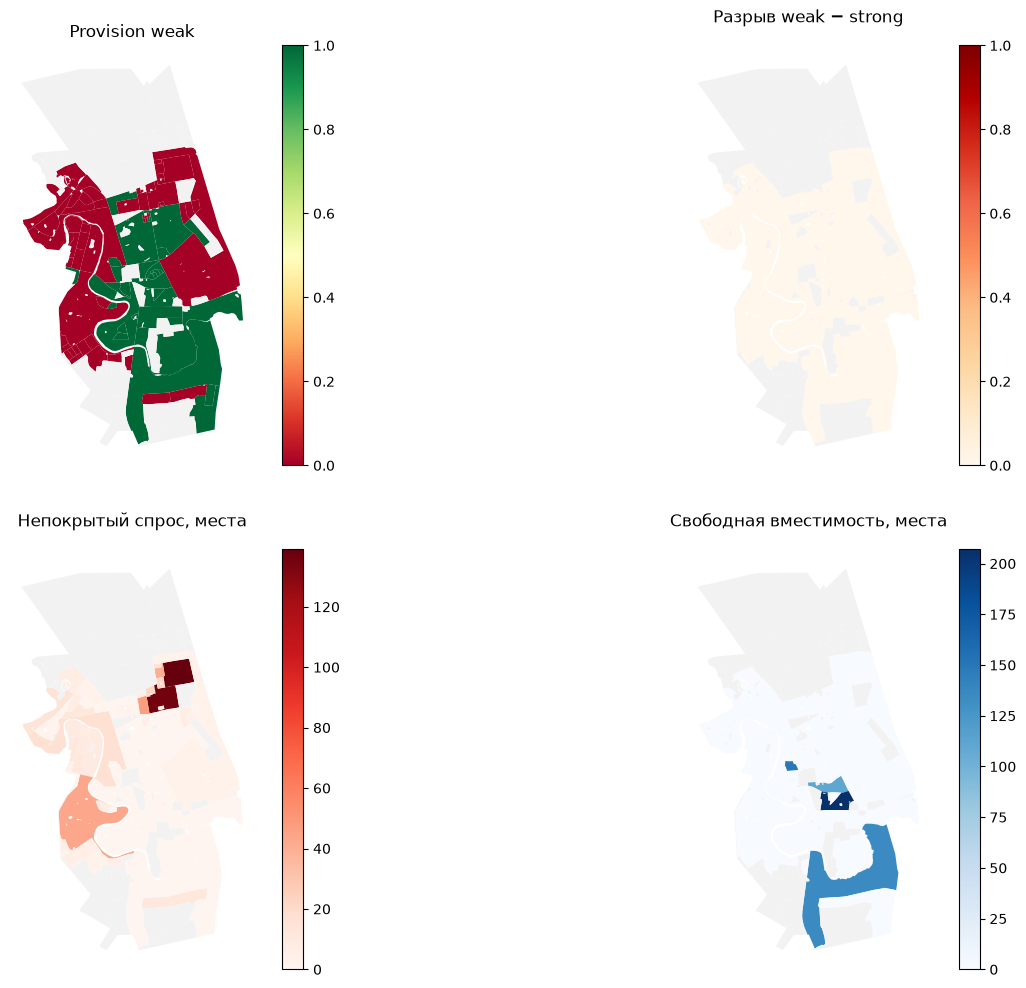

In [23]:
from IPython.display import display

provision_columns = [
    "demand",
    "capacity",
    "demand_left",
    "demand_within",
    "demand_without",
    "capacity_left",
    "capacity_within",
    "capacity_without",
    "provision_strong",
    "provision_weak",
]
provision_columns = [
    column for column in provision_columns if column in prov_df.columns
]
display(prov_df[provision_columns].describe().T)
display(prov_df.head(10))

if links_df.empty:
    print("links_df пуст: все связи покрыты внутри кварталов.")
else:
    print("Крупнейшие связи спроса:")
    display(links_df.sort_values("value", ascending=False).head(10))

provision_map = blocks.join(
    prov_df[
        [
            "provision_strong",
            "provision_weak",
            "demand_left",
            "capacity_left",
        ]
    ]
)
provision_map["provision_gap"] = (
    provision_map["provision_weak"] - provision_map["provision_strong"]
)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
map_specs = [
    ("provision_weak", "Provision weak", "RdYlGn", 0, 1),
    ("provision_gap", "Разрыв weak − strong", "OrRd", 0, 1),
    ("demand_left", "Непокрытый спрос, места", "Reds", None, None),
    ("capacity_left", "Свободная вместимость, места", "Blues", None, None),
]
for ax, (column, title, cmap, vmin, vmax) in zip(axes.flat, map_specs):
    plot_kwargs = {
        "column": column,
        "cmap": cmap,
        "legend": True,
        "ax": ax,
        "missing_kwds": {"color": "#f2f2f2"},
    }
    if vmin is not None:
        plot_kwargs["vmin"] = vmin
        plot_kwargs["vmax"] = vmax
    provision_map.plot(**plot_kwargs)
    ax.set_title(title)
    ax.set_axis_off()
plt.show()


## 9. Плотность и морфотипы

`calculate_density_indicators` считает FSI, GSI, MXI, этажность `l`, OSR и доли жилой и нежилой площади. Карта FSI — ниже; затем таблица всех индикаторов, карты остальных показателей и профили кластеров. Морфотипы Spacematrix и Strelka показываются отдельными картами.


Кварталов с застройкой: 186
Кластеров Spacematrix: 11
Медианы: {'fsi': 0.12931021978470192, 'gsi': 0.12260306828065501, 'mxi': 0.0, 'l': 1.0, 'osr': 6.748874234478766}


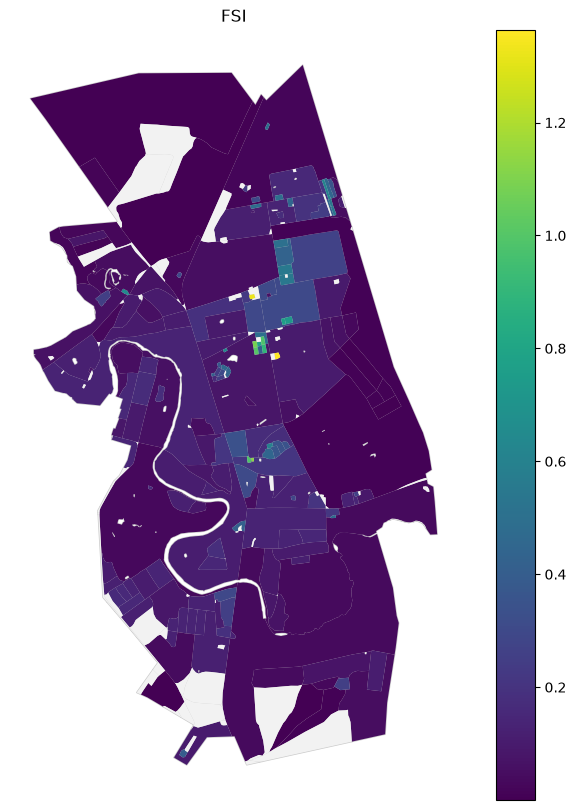

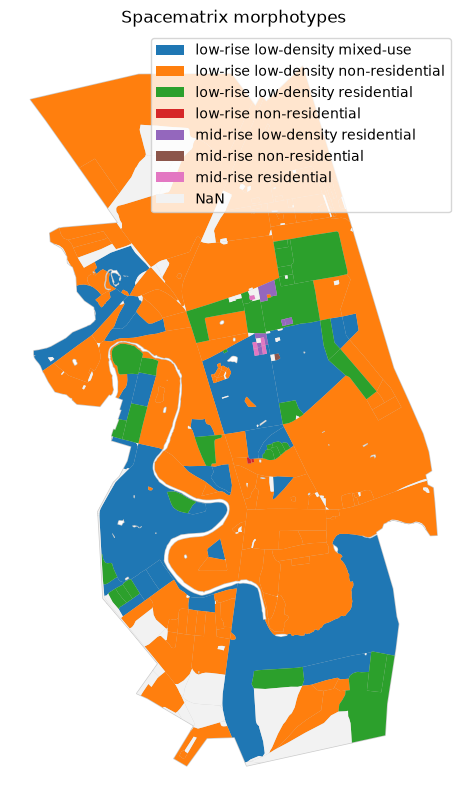

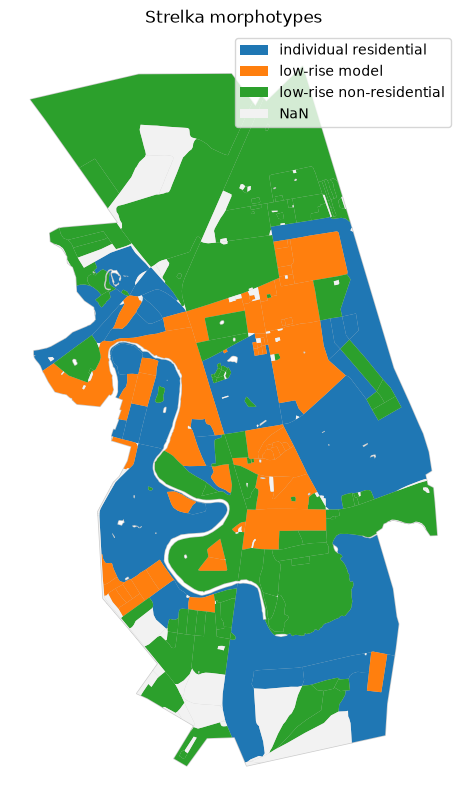

In [24]:
density_mask = (buildings_blocks["build_floor_area"] > 0) & (
    buildings_blocks["footprint_area"] > 0
)
density_input = buildings_blocks.loc[density_mask].copy()
if density_input.empty:
    raise ValueError("Нет кварталов с застройкой для плотности")

density_df = calculate_density_indicators(density_input)
density_df.to_csv(OUT_DIR / "density_indicators.csv")

n_clusters = max(1, min(11, len(density_df)))
spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(
    density_df,
    n_clusters=n_clusters,
)
strelka_df = get_strelka_morphotypes(density_df)

spacematrix_df.to_csv(OUT_DIR / "spacematrix_morphotypes.csv")
spacematrix_clusters.to_csv(OUT_DIR / "spacematrix_clusters.csv")
strelka_df.to_csv(OUT_DIR / "strelka_morphotypes.csv")

density_medians = {
    "fsi": safe_float(density_df["fsi"].median()),
    "gsi": safe_float(density_df["gsi"].median()),
    "mxi": safe_float(density_df["mxi"].median()),
    "l": safe_float(density_df["l"].median()),
    "osr": safe_float(density_df["osr"].median()),
}
print(f"Кварталов с застройкой: {len(density_df)}")
print(f"Кластеров Spacematrix: {n_clusters}")
print(f"Медианы: {density_medians}")

density_map = blocks.join(density_df[["fsi"]])
ax = blocks.plot(
    color="#eeeeee",
    edgecolor="#cccccc",
    figsize=(10, 10),
)
density_map.plot(
    column="fsi",
    cmap="viridis",
    legend=True,
    ax=ax,
    missing_kwds={"color": "#f2f2f2"},
)
ax.set_title("FSI")
ax.set_axis_off()
plt.show()

spacematrix_map = blocks.join(spacematrix_df[["morphotype"]])
ax = blocks.plot(
    color="#eeeeee",
    edgecolor="#cccccc",
    figsize=(10, 10),
)
spacematrix_map.plot(
    column="morphotype",
    categorical=True,
    legend=True,
    ax=ax,
    missing_kwds={"color": "#f2f2f2"},
)
ax.set_title("Spacematrix morphotypes")
ax.set_axis_off()
plt.show()

strelka_map = blocks.join(strelka_df[["morphotype"]])
ax = blocks.plot(
    color="#eeeeee",
    edgecolor="#cccccc",
    figsize=(10, 10),
)
strelka_map.plot(
    column="morphotype",
    categorical=True,
    legend=True,
    ax=ax,
    missing_kwds={"color": "#f2f2f2"},
)
ax.set_title("Strelka morphotypes")
ax.set_axis_off()
plt.show()


,count,mean,std,min,25%,50%,75%,max
fsi,186.0,0.230572,0.251178,0.000176,0.080098,0.129310,0.303269,1.363915
gsi,186.0,0.160651,0.131624,0.000176,0.067503,0.122603,0.223658,0.613599
mxi,186.0,0.262551,0.349839,0.000000,0.000000,0.000000,0.545349,0.900000
l,186.0,1.302501,0.557255,1.000000,1.000000,1.000000,1.283883,3.000000
osr,186.0,55.306453,427.037286,0.381252,2.537782,6.748874,11.537375,5683.559332
share_living,186.0,0.449331,0.753902,0.000000,0.000000,0.000000,0.575390,2.700000
share_non_living,186.0,0.853170,0.449356,0.100000,0.515663,1.000000,1.000000,3.000000


,fsi,gsi,mxi,l,osr,share_living,share_non_living
0,0.110559,0.080869,0.029098,1.367134,8.313500,0.039781,1.327353
1,0.209337,0.147433,0.142202,1.419877,4.072709,0.201910,1.217967
2,0.307329,0.208951,0.000000,1.470822,2.573946,0.000000,1.470822
3,0.043395,0.043395,0.000000,1.000000,22.044155,0.000000,1.000000
4,0.050554,0.050554,0.000000,1.000000,18.780778,0.000000,1.000000
6,0.113281,0.106347,0.000000,1.065204,7.888782,0.000000,1.065204
10,0.118547,0.118547,0.028097,1.000000,7.435474,0.028097,0.971903
11,0.031039,0.031039,0.221276,1.000000,31.217349,0.221276,0.778724
13,0.128769,0.096888,0.068177,1.329051,7.013441,0.090611,1.238440
14,0.072845,0.072845,0.000000,1.000000,12.727799,0.000000,1.000000


,l,fsi,mxi,cluster,morphotype
0,1.367134,0.110559,0.029098,3,low-rise low-density non-residential
1,1.419877,0.209337,0.142202,3,low-rise low-density non-residential
2,1.470822,0.307329,0.000000,0,low-rise low-density non-residential
3,1.000000,0.043395,0.000000,3,low-rise low-density non-residential
4,1.000000,0.050554,0.000000,3,low-rise low-density non-residential
6,1.065204,0.113281,0.000000,3,low-rise low-density non-residential
10,1.000000,0.118547,0.028097,3,low-rise low-density non-residential
11,1.000000,0.031039,0.221276,3,low-rise low-density non-residential
13,1.329051,0.128769,0.068177,3,low-rise low-density non-residential
14,1.000000,0.072845,0.000000,3,low-rise low-density non-residential


,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype
cluster,,,,,,,
0,1.000000,0.357178,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
1,3.000000,0.613062,0.900000,mid-rise,low-density,residential,mid-rise low-density residential
2,1.000000,0.092298,0.810889,low-rise,low-density,residential,low-rise low-density residential
3,1.000000,0.098986,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
4,1.909028,0.246521,0.764597,low-rise,low-density,residential,low-rise low-density residential
5,2.000000,1.057666,0.000000,low-rise,None,non-residential,low-rise non-residential
6,1.052068,0.100999,0.432833,low-rise,low-density,mixed-use,low-rise low-density mixed-use
7,2.000000,0.391976,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
8,2.000000,0.473401,0.900000,low-rise,low-density,residential,low-rise low-density residential


,l,fsi,mxi,morphotype
0,1.367134,0.110559,0.029098,low-rise non-residential
1,1.419877,0.209337,0.142202,low-rise model
2,1.470822,0.307329,0.000000,low-rise non-residential
3,1.000000,0.043395,0.000000,low-rise non-residential
4,1.000000,0.050554,0.000000,low-rise non-residential
6,1.065204,0.113281,0.000000,low-rise non-residential
10,1.000000,0.118547,0.028097,low-rise non-residential
11,1.000000,0.031039,0.221276,individual residential
13,1.329051,0.128769,0.068177,low-rise model
14,1.000000,0.072845,0.000000,low-rise non-residential


cluster  morphotype                          
0        low-rise low-density non-residential    30
1        mid-rise low-density residential         6
2        low-rise low-density residential        15
3        low-rise low-density non-residential    78
4        low-rise low-density residential         6
5        low-rise non-residential                 2
6        low-rise low-density mixed-use          27
7        low-rise low-density non-residential     6
8        low-rise low-density residential        10
9        mid-rise residential                     5
10       mid-rise non-residential                 1
Name: count, dtype: int64

morphotype
low-rise non-residential    103
low-rise model               55
individual residential       28
Name: count, dtype: int64

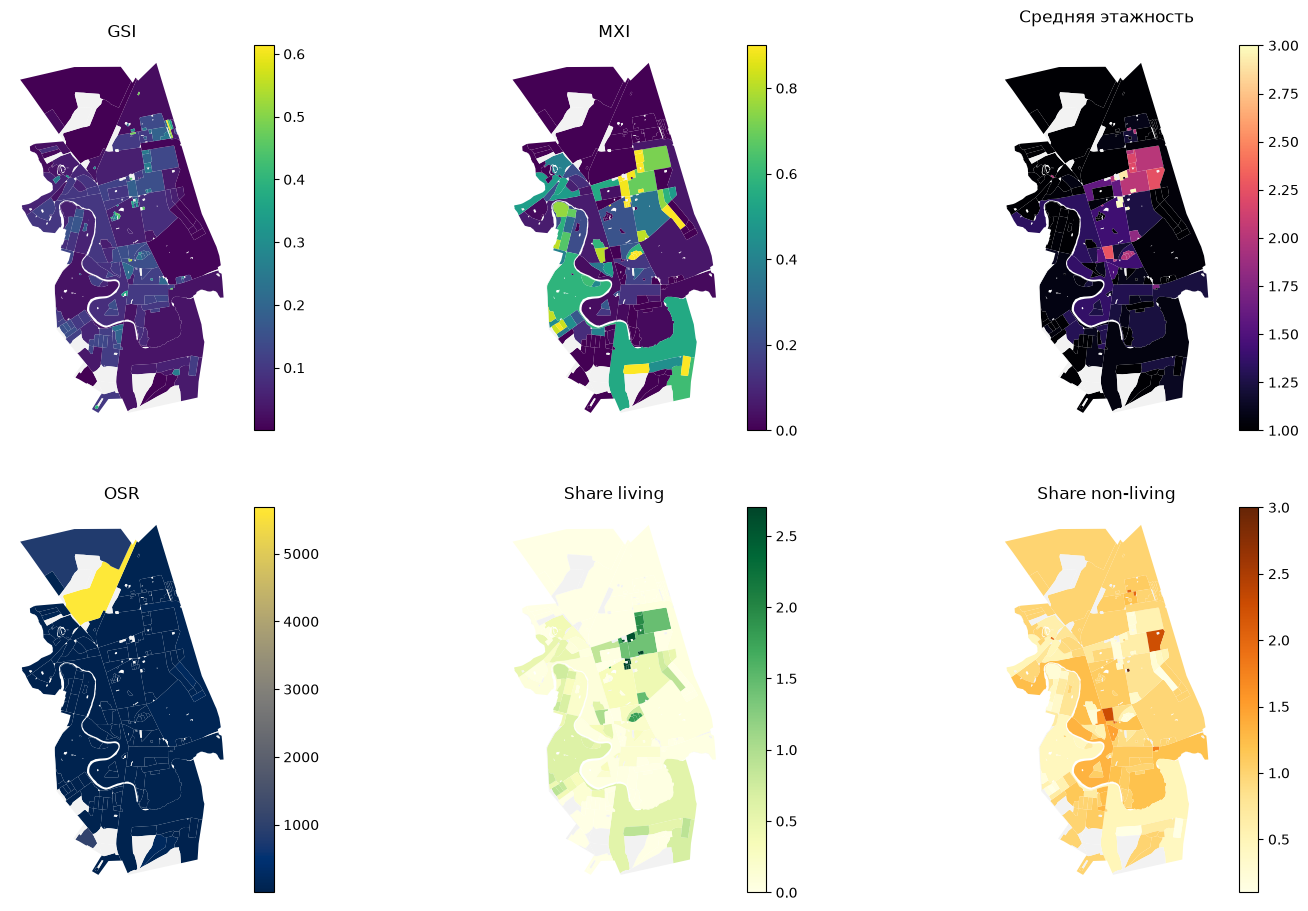

In [25]:
from IPython.display import display

density_columns = [
    "fsi",
    "gsi",
    "mxi",
    "l",
    "osr",
    "share_living",
    "share_non_living",
]
density_columns = [
    column for column in density_columns if column in density_df.columns
]
display(density_df[density_columns].describe().T)
display(density_df[density_columns].head(10))
display(spacematrix_df.head(10))
display(spacematrix_clusters)
display(strelka_df.head(10))
display(
    spacematrix_df[["cluster", "morphotype"]]
    .value_counts()
    .sort_index()
)
display(strelka_df["morphotype"].value_counts(dropna=False))

map_columns = [
    ("gsi", "GSI", "viridis"),
    ("mxi", "MXI", "viridis"),
    ("l", "Средняя этажность", "magma"),
    ("osr", "OSR", "cividis"),
    ("share_living", "Share living", "YlGn"),
    ("share_non_living", "Share non-living", "YlOrBr"),
]
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, (column, title, cmap) in zip(axes.flat, map_columns):
    plot_df = blocks.join(density_df[[column]])
    plot_df[column] = plot_df[column].replace([np.inf, -np.inf], np.nan)
    plot_df.plot(
        column=column,
        cmap=cmap,
        legend=True,
        ax=ax,
        missing_kwds={"color": "#f2f2f2"},
    )
    ax.set_title(title)
    ax.set_axis_off()
plt.show()


## 10. Area accessibility

`area_accessibility` — среднее время от квартала до всех кварталов с весами по площади. Карта показывает положение квартала в городе, таблица ниже — распределение значений. Это не качество услуг и не обеспеченность.


Медиана area accessibility: 35.481175745022334


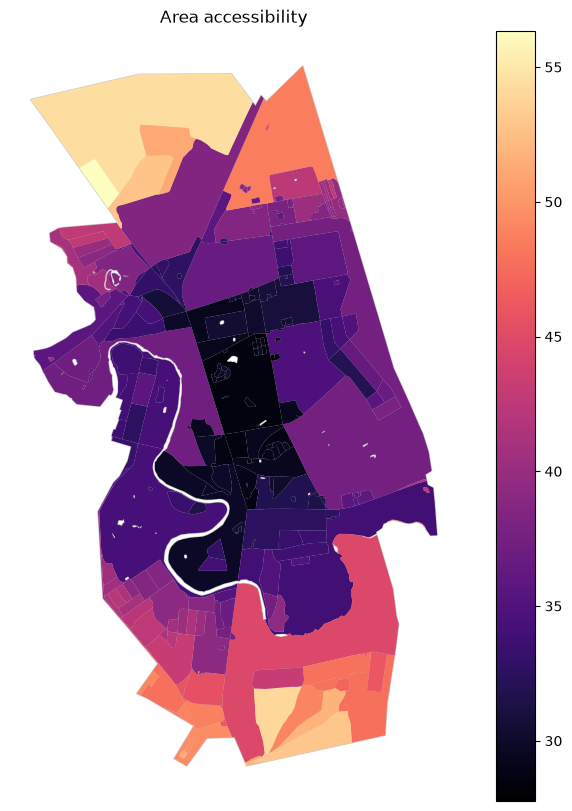

In [26]:
area_acc = area_accessibility(
    acc_mx,
    blocks_for_matrix[["site_area"]],
)
area_acc["area_accessibility"] = area_acc["area_accessibility"].replace(
    [np.inf, -np.inf], np.nan
)
area_acc.to_csv(OUT_DIR / "area_accessibility.csv")

area_accessibility_median = safe_float(
    area_acc["area_accessibility"].median()
)
print(f"Медиана area accessibility: {area_accessibility_median}")

area_map = blocks.join(area_acc)
ax = blocks.plot(
    color="#eeeeee",
    edgecolor="#cccccc",
    figsize=(10, 10),
)
area_map.plot(
    column="area_accessibility",
    cmap="magma",
    legend=True,
    ax=ax,
    missing_kwds={"color": "#f2f2f2"},
)
ax.set_title("Area accessibility")
ax.set_axis_off()
plt.show()


In [27]:
from IPython.display import display

display(area_acc.describe().T)
display(
    area_acc.sort_values("area_accessibility").head(10)
)
display(
    area_acc.sort_values("area_accessibility", ascending=False).head(10)
)


,count,mean,std,min,25%,50%,75%,max
area_accessibility,299.0,36.53676,6.41013,27.764397,30.964056,35.481176,40.358912,56.338544


,area_accessibility
34,27.764397
33,27.834826
37,28.205506
183,28.244267
102,28.437202
251,28.486012
136,28.551109
283,28.571888
279,28.578943
282,28.613740


,area_accessibility
273,56.338544
271,54.390406
190,54.077554
192,52.905633
257,52.773443
270,52.275658
193,51.853812
275,51.828733
220,51.322831
272,51.196982


## 11. Итоговые файлы и проверки

In [28]:
blocks_results = blocks.copy()
blocks_results = blocks_results.join(
    buildings_blocks[["population"]]
)
blocks_results = blocks_results.join(
    schools_blocks[["capacity"]]
)
blocks_results = blocks_results.join(
    prov_df[["provision_strong", "provision_weak"]]
)
blocks_results = blocks_results.join(
    density_df[
        [
            "fsi",
            "gsi",
            "mxi",
            "l",
            "osr",
            "share_living",
            "share_non_living",
        ]
    ]
)
blocks_results = blocks_results.join(
    spacematrix_df[["morphotype"]].rename(
        columns={"morphotype": "spacematrix_morphotype"}
    )
)
blocks_results = blocks_results.join(
    strelka_df[["morphotype"]].rename(
        columns={"morphotype": "strelka_morphotype"}
    )
)
blocks_results = blocks_results.join(area_acc)

write_geojson(
    blocks_results,
    OUT_DIR / "blocks_results.geojson",
)
blocks_results_csv = blocks_results.drop(columns="geometry").copy()
if "land_use" in blocks_results_csv.columns:
    blocks_results_csv["land_use"] = blocks_results_csv["land_use"].apply(
        lambda value: value.value if hasattr(value, "value") else value
    )
blocks_results_csv.to_csv(
    OUT_DIR / "blocks_results.csv",
    index=True,
)

summary = {
    "created_at": now_utc(),
    "territory": DISTRICT_NAME,
    "osm_relation_id": OSM_RELATION_ID,
    "osm_source": "Geofabrik Central Federal District PBF + Pyrosm",
    "boundary_area_km2": boundary_area_km2,
    "block_area_km2": block_area_km2,
    "block_count": int(len(blocks)),
    "blocks_with_buildings": blocks_with_buildings,
    "blocks_with_population": blocks_with_population,
    "population_total": population_total,
    "buildings_count": int(len(buildings)),
    "schools_count": int(len(schools)),
    "school_capacity_total": school_capacity_total,
    "blocks_with_school_capacity": blocks_with_school_capacity,
    "school_demand_per_1000": school_demand,
    "school_accessibility_min": school_accessibility,
    "provision_strong_total": safe_float(provision_total),
    "matrix_scope": MATRIX_SCOPE,
    "matrix_shape": list(acc_mx.shape),
    "matrix_finite_share": matrix_finite_share,
    "matrix_stats": matrix_stats,
    "graph": graph_meta,
    "density_medians": density_medians,
    "area_accessibility_median": area_accessibility_median,
    "land_use_counts": land_use_counts,
    "land_use_nan_share": land_use_nan_share,
    "notes": "Оценки на основе OSM и коэффициентов BlocksNet; не официальная статистика.",
}
with open(
    OUT_DIR / "summary.json", "w", encoding="utf-8"
) as file:
    json.dump(summary, file, ensure_ascii=False, indent=2)

output_files = [
    boundary_path,
    RAW_DIR / "roads.geojson",
    RAW_DIR / "railways.geojson",
    RAW_DIR / "water.geojson",
    RAW_DIR / "functional_zones.geojson",
    RAW_DIR / "buildings.geojson",
    RAW_DIR / "schools.geojson",
    OUT_DIR / "blocks_raw.geojson",
    OUT_DIR / "blocks_land_use.geojson",
    OUT_DIR / "buildings_blocks.geojson",
    OUT_DIR / "schools_blocks.geojson",
    graph_path,
    graph_meta_path,
    CACHE_DIR / "walk_graph_nodes.geojson",
    CACHE_DIR / "walk_graph_edges.geojson",
    matrix_path,
    OUT_DIR / "school_provision.csv",
    OUT_DIR / "school_links.csv",
    OUT_DIR / "density_indicators.csv",
    OUT_DIR / "spacematrix_morphotypes.csv",
    OUT_DIR / "spacematrix_clusters.csv",
    OUT_DIR / "strelka_morphotypes.csv",
    OUT_DIR / "area_accessibility.csv",
    OUT_DIR / "blocks_results.geojson",
    OUT_DIR / "blocks_results.csv",
    OUT_DIR / "summary.json",
]

manifest = {
    "created_at": now_utc(),
    "territory": DISTRICT_NAME,
    "boundary_query": BOUNDARY_QUERY,
    "osm_relation_id": OSM_RELATION_ID,
    "graph_type": "walk",
    "walk_speed_kmh": WALK_SPEED_KMH,
    "osm_pbf_url": PBF_URL,
    "osm_pbf_file": str(PBF_PATH.relative_to(PROJECT_ROOT)),
    "living_demand_m2_per_person": LIVING_DEMAND,
    "school_demand_per_1000": school_demand,
    "school_accessibility_min": school_accessibility,
    "sources": [
        "OpenStreetMap contributors, ODbL",
        "Geofabrik",
        "Pyrosm",
        "Nominatim",
        "IduEdu",
        "BlocksNet",
    ],
    "packages": {
        package: package_version(package)
        for package in [
            "blocksnet",
            "iduedu",
            "osmnx",
            "pyrosm",
            "geopandas",
            "pandas",
            "networkx",
            "folium",
            "matplotlib",
            "mapclassify",
        ]
    },
    "files": [
        str(path.relative_to(PROJECT_ROOT))
        for path in output_files
        if path.exists()
    ],
}
with open(
    OUT_DIR / "manifest.json", "w", encoding="utf-8"
) as file:
    json.dump(manifest, file, ensure_ascii=False, indent=2)

validation_rows = []

def add_validation(check, ok, value, note=""):
    validation_rows.append(
        {
            "check": check,
            "status": "OK" if ok else "WARNING",
            "value": str(value),
            "note": note,
        }
    )

add_validation(
    "boundary_count",
    len(boundaries) == 1,
    len(boundaries),
    "Граница должна состоять из одного объекта",
)
add_validation(
    "boundary_area_km2",
    10 <= boundary_area_km2 <= 25,
    f"{boundary_area_km2:.1f}",
    "Ожидается около 15 км²",
)
add_validation(
    "block_count",
    len(blocks) > 0,
    len(blocks),
)
add_validation(
    "land_use_missing_share",
    land_use_nan_share <= 0.5,
    f"{land_use_nan_share:.1%}",
    "Доля кварталов без land use",
)
add_validation(
    "population_total",
    population_total > 0,
    f"{population_total:.0f}",
)
add_validation(
    "schools_count",
    len(schools) > 0,
    len(schools),
)
add_validation(
    "graph_nodes",
    graph.number_of_nodes() > 0,
    graph.number_of_nodes(),
)
add_validation(
    "graph_edges",
    graph.number_of_edges() > 0,
    graph.number_of_edges(),
)
add_validation(
    "matrix_square",
    acc_mx.shape[0] == acc_mx.shape[1],
    f"{acc_mx.shape}",
)
add_validation(
    "matrix_finite_share",
    matrix_finite_share > 0,
    f"{matrix_finite_share:.1%}",
)
provision_values = prov_df["provision_strong"].dropna()
add_validation(
    "provision_range",
    bool(
        len(provision_values)
        and provision_values.between(0, 1).all()
    ),
    f"{provision_values.min():.3f}..{provision_values.max():.3f}"
    if len(provision_values)
    else "empty",
)
add_validation("matrix_scope", True, MATRIX_SCOPE)
missing_outputs = [path for path in output_files if not path.exists()]
add_validation(
    "outputs_exist",
    len(missing_outputs) == 0,
    f"{len(output_files) - len(missing_outputs)}/{len(output_files)}",
    "Отсутствуют: "
    + ", ".join(str(path.name) for path in missing_outputs)
    if missing_outputs
    else "",
)

validation_df = pd.DataFrame(validation_rows)
validation_df.to_csv(
    OUT_DIR / "validation_report.csv",
    index=False,
)

print("Готово")
print(f"Результаты: {OUT_DIR}")
print(f"Итоговый GeoJSON: {OUT_DIR / 'blocks_results.geojson'}")
print(f"Итоговая таблица: {OUT_DIR / 'blocks_results.csv'}")
print(f"Сводка: {OUT_DIR / 'summary.json'}")
print(f"Проверки: {OUT_DIR / 'validation_report.csv'}")
print(validation_df)


Готово
Результаты: d:\Учеба\ai-course\python-package-boilerplate\examples\data\suzdal\results
Итоговый GeoJSON: d:\Учеба\ai-course\python-package-boilerplate\examples\data\suzdal\results\blocks_results.geojson
Итоговая таблица: d:\Учеба\ai-course\python-package-boilerplate\examples\data\suzdal\results\blocks_results.csv
Сводка: d:\Учеба\ai-course\python-package-boilerplate\examples\data\suzdal\results\summary.json
Проверки: d:\Учеба\ai-course\python-package-boilerplate\examples\data\suzdal\results\validation_report.csv
                     check   status         value                                       note
0           boundary_count       OK             1  Граница должна состоять из одного объекта
1        boundary_area_km2       OK          15.0                     Ожидается около 15 км²
2              block_count       OK           299                                           
3   land_use_missing_share       OK         34.4%                Доля кварталов без land use
4         

## Приложение: метрики BlocksNet и показатели из `pipeline.ipynb`

> В этом репозитории файла `examples/pipeline.ipynb` нет. Разбор ниже опирается на официальный `aimclub/blocksnet/examples/pipeline.ipynb` (ветка `main`) и API установленной версии `blocksnet 1.0.0a9`. Это демонстрационный pipeline, а не полный каталог метрик библиотеки.

### 1. Как читать метрики BlocksNet

Почти все метрики BlocksNet считаются **на уровне квартала** (urban block). Квартал — это небольшой участок города, ограниченный дорогами, водой, железными дорогами и границами территории. Поэтому результат обычно выглядит как таблица: одна строка — один квартал, столбцы — показатели. Потом эти значения можно сложить в статистику по городу или району.

Полезно различать три вещи:

- **Слой данных** — геометрия и атрибуты: кварталы, здания, школы, функциональные зоны. Это ещё не метрика.
- **Матрица отношений** — например, матрица доступности: сколько минут ехать от каждого квартала до каждого. Это промежуточный расчёт.
- **Метрика** — число или категория, которую можно сравнить между кварталами: плотность, обеспеченность, морфотип, доступность.

Единицы в BlocksNet зависят от показателя. Площади — в м² (или км² на уровне города), время — в минутах, расстояния — в метрах, доли и индексы — без единиц или в долях от 0 до 1, количество объектов — в штуках, вместимость услуг — в местах/людях.

### 2. Основные группы метрик BlocksNet

| Группа | Простыми словами | Примеры показателей | Единицы |
|---|---|---|---|
| Плотность и застройка | Насколько интенсивно используется земля и сколько этажей построено | `fsi`, `gsi`, `mxi`, `l`, `osr`, `share_living`, `share_non_living` | м²/м², этажи, доли |
| Морфотипы | К какому типу застройки похож квартал | Spacematrix, Strelka | категории |
| Доступность | Сколько минут занимает путь между кварталами и до объектов | матрица доступности, `area_accessibility`, `mean_accessibility`, `median_accessibility`, `max_accessibility`, `land_use_accessibility`, `relative_accessibility`, `connectivity` | минуты, 1/мин |
| Обеспеченность | Хватает ли услуг жителям и как далеко они находятся | `competitive_provision`: `provision_strong`, `provision_weak`; `shared_provision`: `provision`, `load` | доли 0–1, места, люди |
| Сервисы и разнообразие | Сколько услуг, насколько они разнообразны и часто ли встречаются вместе | `count`, `density`, Shannon diversity, collocation | штуки, 1/м², индекс, 0–1 |
| Сеть и центральность | Насколько связан город и какие кварталы являются «центрами» | connectivity, degree centrality, population centrality, services centrality, OD-матрица, road congestion | 1/мин, 0–1, условные потоки |
| Социально-экономические индикаторы | Демография, транспорт, инфраструктура, экономика, экология | население, плотность населения, дорожная плотность, доступность станций, количество объектов | люди, люди/км², км/км², минуты, штуки |
| Геометрия кварталов | Размер и форма квартала | `site_area`, `site_length`, `aspect_ratio`, `outer_radius`, `inner_radius`, `centerline_length` | м², м, без единиц |
| Пустые территории | Где потенциально есть свободная от застройки земля | `area`, `mrr_area`, `length`, `area_to_length`, `area_to_mrr_area` | м², м, без единиц |
| Землепользование | Какие функции занимают территорию и как они соседствуют | доли land use, land-use indicators, collocation, similarity | доли, м², категории, 0–1 |

#### Плотность и застройка

`calculate_density_indicators` — основной расчёт этой группы. Он берёт площади квартала и зданий и получает:

- `fsi` — сколько квадратных метров площади этажей приходится на квадратный метр земли;
- `gsi` — какая доля земли занята footprint зданий;
- `mxi` — какая доля площади этажей является жилой;
- `l` — средняя этажность;
- `osr` — сколько открытого пространства приходится на единицу площади этажей;
- `share_living` и `share_non_living` — жилая и нежилая площадь на единицу footprint.

`calculate_development_indicators` — связанный расчёт: он восстанавливает базовые площади (`site_area`, `footprint_area`, `build_floor_area`, `living_area`, `non_living_area`) и пересчитывает через них `fsi`, `gsi`, `mxi`. Это не отдельная новая метрика, а другой срез тех же данных.

#### Морфотипы

- **Spacematrix** кластеризует кварталы по `l`, `fsi` и `mxi` и даёт каждому кварталу номер кластера и словесный морфотип. Кластеры не упорядочены: «кластер 4» не значит «лучше» или «плотнее» кластера 2.
- **Strelka** не кластеризует, а применяет правила по этажности, плотности и доле жилья. Получаются категории вроде `low-rise residential`, `mid-rise microdistrict`, `high-rise non-residential`.

Это качественные, а не универсальные метрики: названия зависят от обучающей выборки и порогов, заложенных в библиотеку.

#### Доступность

- **Матрица доступности** — время пути между каждой парой кварталов. В pipeline используется intermodal-граф (пешком + общественный транспорт), в нашем ноутбуке — пешеходный граф.
- **`area_accessibility`** — средневзвешенное по площади время от квартала до всех кварталов. Это показатель положения, а не качества услуг: низкое значение означает, что квартал в среднем «близко ко всему».
- **`mean/median/max_accessibility`** — свёртки строк матрицы в одно число.
- **`land_use_accessibility`** — доступность кварталов с заданным land use.
- **`relative_accessibility`** — доступность относительно выбранного квартала.
- **`connectivity`** — величина, обратная средней доступности; больше — лучше.

#### Обеспеченность

- **`competitive_provision`** — распределяет спрос между конкурирующими объектами услуги с учётом доступности и вместимости. Основные результаты: `provision_strong` и `provision_weak`.
  - `provision_strong` — какая доля спроса покрыта объектами **в пределах норматива доступности**;
  - `provision_weak` — какая доля спроса покрыта вообще, даже если объект дальше норматива;
  - разница `weak − strong` показывает, какая часть спроса вынуждена пользоваться далёкими объектами.
- **`shared_provision`** — более простая модель «общего» обслуживания: считает население и вместимость в радиусе доступности, а также `load` (нагрузку на вместимость) и `provision` (вместимость на человека).

#### Сервисы, разнообразие и землепользование

- `services_count` — количество объектов каждого типа и общее количество.
- `services_density` — количество объектов на единицу площади квартала.
- `shannon_diversity` — индекс разнообразия сервисов: 0, если сервис только одного типа; чем больше типов и чем равномернее они представлены, тем выше значение.
- `services_collocation` — матрица совместной встречаемости типов сервисов в кварталах (IoU, 0–1).
- `land_use_similarity` — насколько профиль сервисов квартала похож на типовой профиль land use; выдаёт категорию и `probability`.
- `land_use_collocation` — доля соседней площади с допустимыми по правилам типами land use.

#### Сеть, центральность и потоки

- `connectivity` — производная доступности, 1/мин.
- `degree_centrality` — доля соседей квартала в графе смежности, 0–1.
- `population_centrality` — нормализованная комбинация населения и degree centrality, 0–1.
- `services_centrality` — композит из connectivity, diversity и density сервисов, 0–1.
- `origin_destination_matrix` — модельные потоки между кварталами/узлами.
- `road_congestion` — суммарный поток, приписанный рёбрам графа. Это не автомобили в час, а условная мера нагрузки.

#### Социально-экономические индикаторы

В BlocksNet есть отдельные наборы индикаторов:

- **General**: площадь (`area`, км²), урбанизация (`urbanization`, доля).
- **Demographic**: население (человек), плотность населения (человек/км²), рождаемость, смертность, миграция (на человека).
- **Social**: количество и обеспеченность для детских садов, школ, колледжей, вузов, больниц, поликлиник, аптек, спорта, социальных учреждений, почты, банков, культуры, безопасности, туризма и др. Обеспеченность — доля 0–1.
- **Transport**: плотность дорожной сети (км/км²), длина дорог (км), связность, средние расстояния, количество и доступность АЗС, железнодорожных станций, аэропортов, портов.
- **Engineering**: количество объектов инфраструктуры — подстанций, водозаборов, очистных, резервуаров, газораспределения.
- **Economic / Ecological / Settlement**: перечни индикаторов для инвестиций, ВРП, бюджета, зарплат, охраняемых территорий, загрязнения, размеров населённых пунктов. В текущей версии не для всех из них есть готовый расчётный метод; часть существует как схема/перечень.

#### Геометрия, пустые территории и слои

- Геометрия: площадь, длина, вытянутость (`aspect_ratio`), внешний и внутренний радиусы, длина центральной линии.
- Пустые территории: площадь, площадь минимального ограничивающего прямоугольника, длина, отношения площади к длине и к прямоугольнику. Это кандидаты на развитие, но их нужно проверять вручную.
- `aggregate_objects` — не метрика, а агрегация зданий/сервисов по кварталам. `blocks`, `functional_zones`, `buildings_blocks`, `schools_blocks` — слои данных.

### 3. Все показатели из `pipeline.ipynb`

Официальный pipeline показывает не все метрики BlocksNet, а только базовый сценарий: **кварталы → землепользование → матрица доступности → агрегация зданий и школ → обеспеченность → плотность и морфотипы → area accessibility**. В нём используются intermodal-граф и пример со школами.

Что именно создаётся в pipeline:

- слои `blocks`, `functional_zones`, `buildings_blocks`, `schools_blocks`;
- матрица `acc_mx` и таблица `prov_df`, `links_df`;
- таблица `density_df`;
- таблицы `spacematrix_df`, `spacematrix_clusters`, `strelka_df`;
- таблица `area_acc`.

#### 3.1. Доступность и обеспеченность

| Показатель | Что означает | Единицы | Что помогает узнать о Суздале |
|---|---|---|---|
| `acc_mx[i, j]` | Время пути от квартала `i` до квартала `j` | минуты | Какие кварталы изолированы, где 15-минутная зона школ, какие пары кварталов связаны плохо |
| `area_accessibility` | Среднее время от квартала до всех кварталов, взвешенное по площади | минуты | Насколько квартал в среднем «близко ко всему»; низкое значение — хорошее положение, высокое — периферия |
| `provision_strong` | Доля спроса, покрытая школами в пределах норматива доступности | доля 0–1 | Есть ли у квартала школа в 15 минутах; главный показатель школьной обеспеченности |
| `provision_weak` | Доля спроса, покрытая школами даже за пределами норматива | доля 0–1 | Покрыт ли спрос вообще; разница с `strong` показывает вынужденные дальние поездки |
| `demand` | Нормативная потребность в местах | места | Сколько мест нужно жителям квартала |
| `capacity` | Вместимость школ квартала | места | Сколько мест есть |
| `demand_left` | Непокрытый спрос после распределения | места | Остаток, который не удалось обслужить |
| `demand_within` | Спрос, покрытый в пределах порога | места | Сколько мест реально обеспечено рядом |
| `demand_without` | Спрос, покрытый за пределами порога | места | Сколько детей обслуживается далёкими школами |
| `capacity_left` | Неиспользованная вместимость | места | Запас мест |
| `capacity_within` | Вместимость, использованная в пределах порога | места | Сколько мест задействовано рядом |
| `capacity_without` | Вместимость, использованная за пределами порога | места | Сколько мест задействовано далёкими поездками |
| `links_df.source` | Квартал-источник спроса | ID | Откуда едут |
| `links_df.target` | Квартал/объект-получатель вместимости | ID | Куда распределяется спрос |
| `links_df.value` | Сколько единиц спроса распределено | места | Какие связи возникают из-за дефицита |

В BlocksNet есть ещё функции `provision_strong_total` и `provision_weak_total` для городской доли, но сам `pipeline.ipynb` их не вызывает; он показывает обеспеченность по кварталам.

В конфиге pipeline для школ задано **120 мест на 1000 жителей** и порог доступности **15 минут**. Поэтому `demand` — это `ceil(население / 1000 * 120)`, а `capacity` берётся из OSM или восстанавливается, если в данных нет вместимости.

Важно: `provision_strong` и `provision_weak` — доли, а не «качество школы». Они говорят только о территориальной доступности и вместимости, но не о качестве образования. Для кварталов без спроса значения могут быть `NaN`.

#### 3.2. Плотность, застройка и морфотипы

Перед расчётом в pipeline задаётся `buildings_blocks["site_area"] = buildings_blocks.area`. То есть `site_area` — площадь квартала, а не площадь здания.

| Показатель | Что означает | Единицы | Что помогает узнать о Суздале |
|---|---|---|---|
| `site_area` | Площадь квартала | м² | Знаменатель для плотности; показывает размер квартала |
| `footprint_area` | Площадь застройки (проекция зданий на землю) | м² | Сколько земли реально занято зданиями |
| `build_floor_area` | Суммарная площадь всех этажей | м² | Общая площадь этажей всех зданий квартала |
| `living_area` | Жилая площадь | м² | Сколько площади этажей приходится на жильё |
| `non_living_area` | Нежилая площадь | м² | Сколько площади этажей приходится на нежилые функции |
| `fsi` | Отношение площади этажей к площади квартала | м²/м² | Интенсивность застройки; выше — плотнее |
| `gsi` | Доля земли под footprint зданий | 0–1 | Насколько квартал «застроен» по земле |
| `mxi` | Доля жилой площади в общей площади этажей | 0–1 | 0 — нет жилья, 1 — только жильё; это доля жилья, а не полный индекс смешанности |
| `l` | Средняя этажность (`build_floor_area / footprint_area`) | этажи | Низко- или высокоэтажная застройка |
| `osr` | Отношение открытого пространства к площади этажей | м²/м² | Больше — просторнее, меньше — «плотнее» и больше давления на дворы |
| `share_living` | Жилая площадь на единицу footprint | м²/м² | Может быть больше 1; показывает «жилую интенсивность» |
| `share_non_living` | Нежилая площадь на единицу footprint | м²/м² | Нежилая интенсивность; тоже может быть больше 1 |
| `cluster` | Номер кластера Spacematrix | целое | Группа кварталов со схожими `l`, `fsi`, `mxi`; номер не является рейтингом |
| `morphotype` (Spacematrix) | Словесный тип кластера | категория | Например, `low-rise low-density residential`; помогает увидеть типы городской ткани |
| `morphotype` (Strelka) | Тип по правилам Strelka | категория | Например, `mid-rise microdistrict`, `high-rise non-residential`; удобно для карты типов застройки |

У пустых или почти пустых кварталов `mxi`, `l`, `osr` и доли могут быть `NaN` или `inf`. Это нормально: у них нет площади этажей или footprint. Для сравнения кварталов лучше фильтровать такие строки.

#### 3.3. Входные и агрегированные поля pipeline

| Поле | Что означает | Единицы | Роль |
|---|---|---|---|
| `population` | Расчётное население квартала | человек | Вход для спроса на школы и демографии |
| `number_of_floors` | Этажность здания | этажи | Вход для `build_floor_area` и морфотипов |
| `count` | Количество объектов после агрегации | штуки | Вход для сервисных метрик |
| `capacity` (школы) | Вместимость школ | места | Вход для обеспеченности |
| `functional_zone` | Исходная функция из OSM | категория | Сырой слой землепользования |
| `land_use` | Категория BlocksNet | категория | Результат назначения землепользования |
| `site_area` у `buildings_blocks` | Площадь квартала | м² | Знаменатель плотности |
| `spacematrix_clusters` | Профили кластеров: медианные `l`, `fsi`, `mxi`, интерпретации и `morphotype` | этажи, м²/м², доли, категории | Объясняет, что означает каждый кластер |
| `strelka_df` | Та же таблица кварталов с `morphotype` по Strelka | категории | Альтернативная типология застройки |

Это не отдельные «метрики города», а входные и агрегированные поля. Например, `population` — оценка, а не официальная статистика; `capacity` школы может быть восстановлена по нормативу, если в OSM её нет.

#### 3.4. Чего в `pipeline.ipynb` нет

В pipeline **не рассчитываются** `shared_provision`, `services_count`, `services_density`, `shannon_diversity`, collocation, центральность, OD-матрица, дорожная загруженность, социально-экономические индикаторы и пустые территории. Это не ошибка: pipeline — базовый демонстрационный сценарий, а перечисленные метрики требуют отдельных данных и кода. Если они нужны для Суздаля, их стоит добавлять следующим этапом.

### 4. Что эти показатели дадут понять о Суздале

| Вопрос | На что смотреть | Как читать |
|---|---|---|
| Где исторический низкорослый центр? | `l`, `fsi`, `gsi`, Spacematrix/Strelka | Низкие `l` и `fsi`, высокая доля жилья или туристических функций; морфотипы low-rise |
| Где плотная современная застройка? | `fsi`, `l`, `gsi` | Высокие `fsi` и `l`; проверьте, не является ли это отдельными крупными зданиями |
| Где жильё, а где бизнес и туризм? | `mxi`, `land_use`, `share_living` | `mxi` близко к 1 — жильё; близко к 0 — нежилые функции; смотрите также land use |
| Какие кварталы пешеходно изолированы? | `area_accessibility`, `acc_mx`, `connectivity` | Высокие минуты и низкая connectivity; особенно важно для окраин и барьеров |
| Хватает ли школ в 15 минутах? | `provision_strong` | 1 — весь спрос покрыт рядом; 0 — доступной вместимости в пределах норматива нет; значения между 0 и 1 — частичный дефицит |
| Где дефицит мест, а где запас? | `demand`, `capacity`, `demand_left`, `capacity_left` | Сравните спрос и вместимость по кварталам; остаток показывает дефицит/запас |
| Куда детей вынужденно везут далеко? | `provision_weak − provision_strong`, `links_df` | Большая разница и длинные связи — сигнал о нехватке мест рядом |
| Где потенциально можно уплотнять? | `fsi`, `osr`, пустые территории | Низкий `fsi` при высоком `osr` — потенциал, но исторический центр и охраняемые территории требуют ограничений |
| Насколько город монофункционален? | `land_use` shares, `mxi` | Один доминирующий тип land use и крайние `mxi` — монофункциональность |
| Где барьеры и плохая связность? | граф, `connectivity`, `area_accessibility` | Низкая связность у реки, железной дороги, промзон; проверьте мосты и переходы |

### 5. Ограничения

- OSM может быть неполным: часть зданий, школ и сервисов отсутствует. `population` и `capacity` — расчётные оценки, а не официальные данные.
- `mxi` в BlocksNet — это доля жилой площади, а не энтропийный индекс смешанности. Не интерпретируйте его как «разнообразие функций».
- `share_living` и `share_non_living` — не доли в процентах, а отношения площадей; они могут быть больше 1.
- `l` и `osr` для пустых кварталов могут быть `NaN`/`inf`; это не ошибка, а отсутствие площади этажей или footprint.
- Морфотипы Spacematrix зависят от числа кластеров и выборки; Strelka — от заложенных порогов. Оба метода считают только кварталы с `fsi > 0`, у пустых кварталов морфотип будет `NaN`. Это инструменты сравнения, а не абсолютная истина.
- `area_accessibility` измеряет среднюю удалённость, а не качество района и не обеспеченность услугами.
- В официальном pipeline используется intermodal-граф; в нашем ноутбуке — пешеходный. Значения доступности не будут совпадать с pipeline.
- В этом объяснении нет чисел: все значения появятся после выполнения ноутбука; таблица объясняет только смысл и единицы.


## Что дальше

- `blocks_results.geojson` содержит кварталы, население, вместимость школ, обеспеченность, плотность, морфотипы и area accessibility.
- `summary.json` содержит ключевые параметры и итоговые значения.
- `validation_report.csv` показывает, какие проверки прошли, а какие требуют внимания.
- Если `MATRIX_SCOPE = "populated"`, у пустых кварталов в показателях доступности и обеспеченности будет `NaN`; это ожидаемо.

Данные OSM могут быть неполными: население и вместимость школ — расчётные оценки. Перед содержательными выводами стоит сверить число школ и население с официальными источниками.

Следующий отдельный этап — интерактивная HTML-страница с картой и дашбордом по `blocks_results.geojson` и `summary.json`.